DATASET DIRECTORY STRUCTURE
ds007526-1.0.1/
    README.md
    dataset_description.json
    participants.json
    participants.tsv
    CHANGES
    sub-093/
        sub-093_scans.tsv
        eeg/
            sub-093_task-rest_events.json
            sub-093_task-rest_events.tsv
            sub-093_task-rest_eeg.set
            sub-093_task-rest_eeg.json
            sub-093_task-walk_events.tsv
    sub-128/
        sub-128_scans.tsv
        eeg/
            sub-128_task-walk_eeg.set
            sub-128_task-walk_events.tsv
            sub-128_task-rest_eeg.json
            sub-128_task-walk_channels.tsv
            sub-128_task-rest_events.tsv
    sub-060/
        sub-060_scans.tsv
        eeg/
            sub-060_task-rest_eeg.set
            sub-060_task-rest_events.json
            sub-060_task-rest_events.tsv
            sub-060_task-walk_events.json
            sub-060_task-walk_events.tsv
    sub-137/
        sub-137_scans.tsv
        eeg/
            sub-137_space-CapTrak_electrode

,Subject,Files
0,sub-093,2
1,sub-093_task-rest_eeg.set,1
2,sub-093_task-walk_eeg.set,1
3,sub-128,2
4,sub-128_task-walk_eeg.set,1


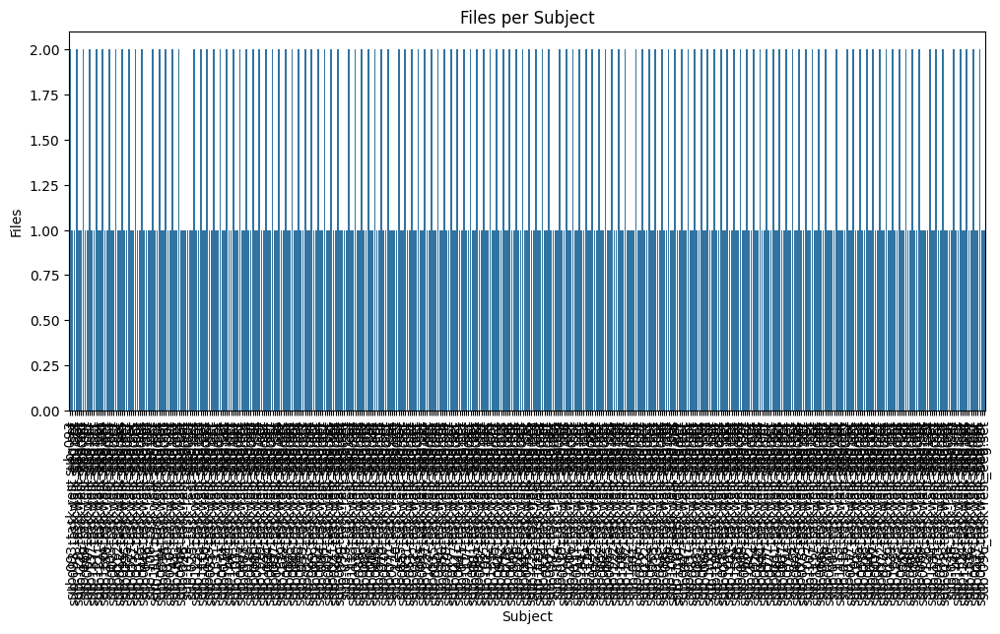


LOADING EEG

Sample File:

/kaggle/input/datasets/sajidshahriar72543/ds007526-1-0-1/ds007526-1.0.1/sub-093/eeg/sub-093_task-rest_eeg.set

EEG Loaded Successfully

BASIC EEG INFORMATION
<RawEEGLAB | sub-093_task-rest_eeg.set, 65 x 60237 (240.9 s), ~29.9 MiB, data loaded>

Sampling Frequency:
250.0

Number of Channels:
65

Recording Duration (sec):
240.944

Channel Names:
['F10', 'AF4', 'F2', 'FCz', 'Fp2', 'Fz', 'FC1', 'AFz', 'F1', 'Fp1', 'AF3', 'F3', 'F5', 'FC5', 'FC3', 'C1', 'F9', 'F7', 'FT7', 'C3', 'CP1', 'C5', 'T9', 'T7', 'TP7', 'CP5', 'P5', 'P3', 'TP9', 'P7', 'P1', 'P9', 'PO3', 'Pz', 'O1', 'POz', 'Oz', 'PO4', 'O2', 'P2', 'CP2', 'P4', 'P10', 'P8', 'P6', 'CP6', 'TP10', 'TP8', 'C6', 'C4', 'C2', 'T8', 'FC4', 'FC2', 'T10', 'FT8', 'FC6', 'F8', 'F6', 'F4', 'EOG1', 'EOG2', 'EOG3', 'EOG4', 'VREF']

CHANNEL TYPE ANALYSIS
Counter({'eeg': 65})


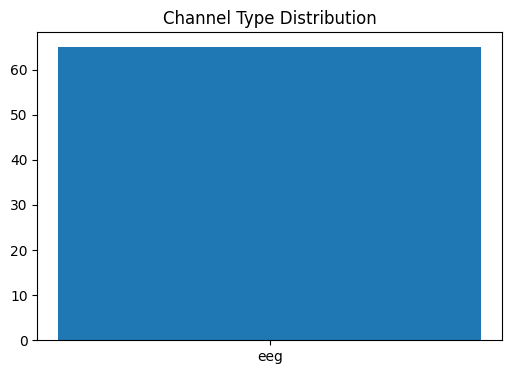


CHANNEL STATISTICS


,Channel,Mean,STD,Min,Max
0,F10,-0.018920,0.001181,-0.020985,-0.016294
1,AF4,-0.004258,0.002170,-0.009116,-0.001739
2,F2,-0.001242,0.001913,-0.005585,0.000959
3,FCz,-0.025003,0.001519,-0.027330,-0.021899
4,Fp2,0.000849,0.002074,-0.003519,0.003421



DEAD CHANNEL DETECTION

Dead Channels Found: 1


,Channel,Mean,STD,Min,Max
64,VREF,0.0,0.0,0.0,0.0



MISSING VALUE ANALYSIS
NaN Values: 0
Infinite Values: 0

RAW EEG VISUALIZATION
Using matplotlib as 2D backend.


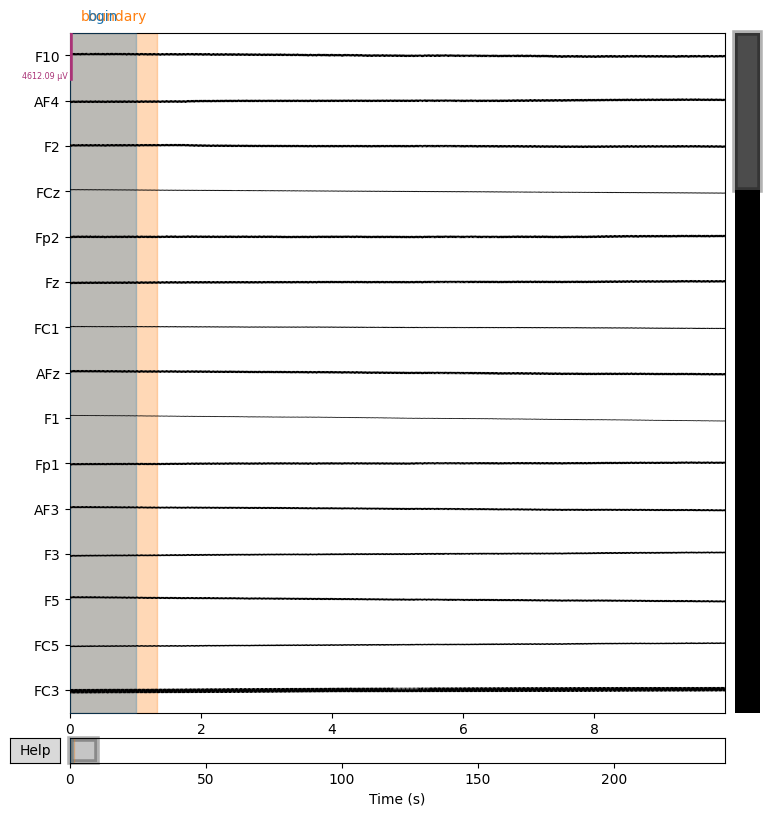


SINGLE CHANNEL PLOT


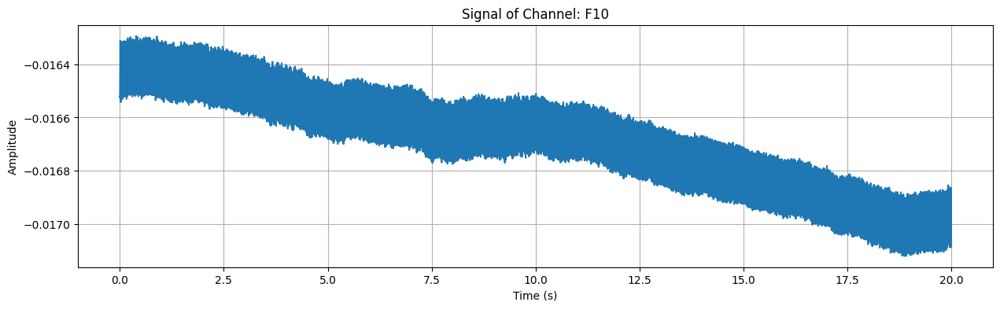


POWER SPECTRAL DENSITY
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).

SENSOR LAYOUT


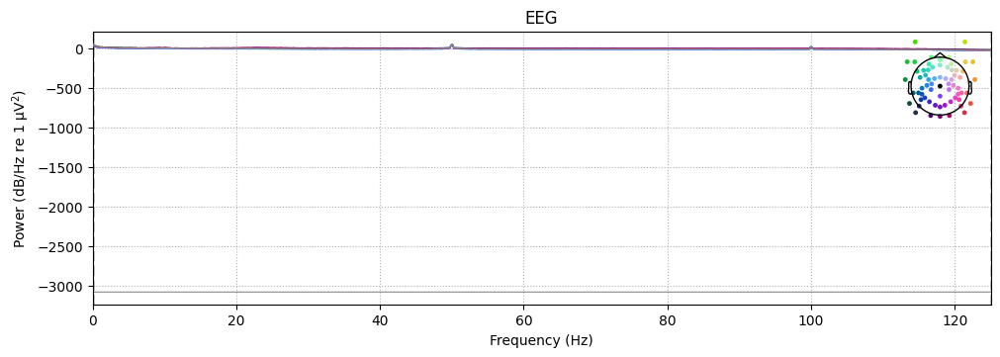

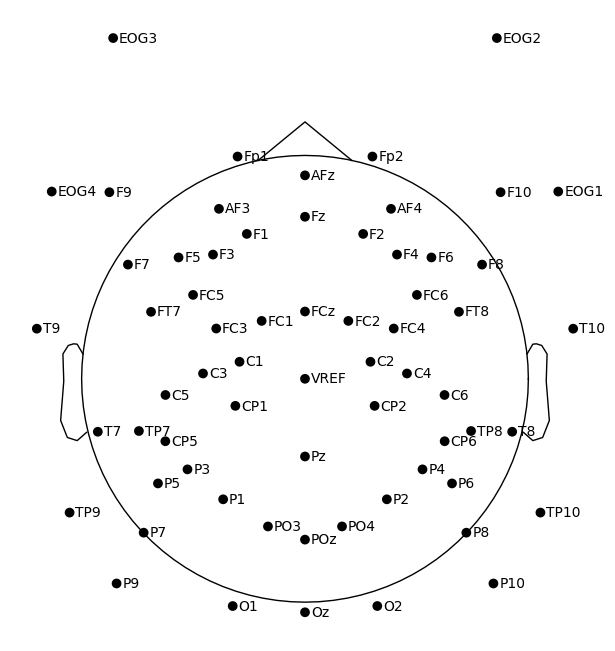


EVENT ANALYSIS
Used Annotations descriptions: [np.str_('bgin'), np.str_('boundary')]

Event Dictionary:
{np.str_('bgin'): 1, np.str_('boundary'): 2}

Total Events:
2


boundary    1
bgin        1
Name: count, dtype: int64

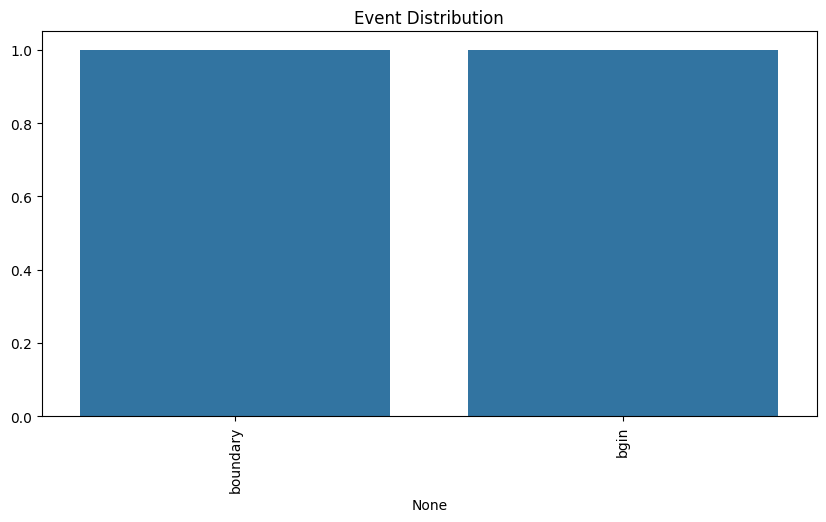


FILTERED EEG
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 825 samples (3.300 s)



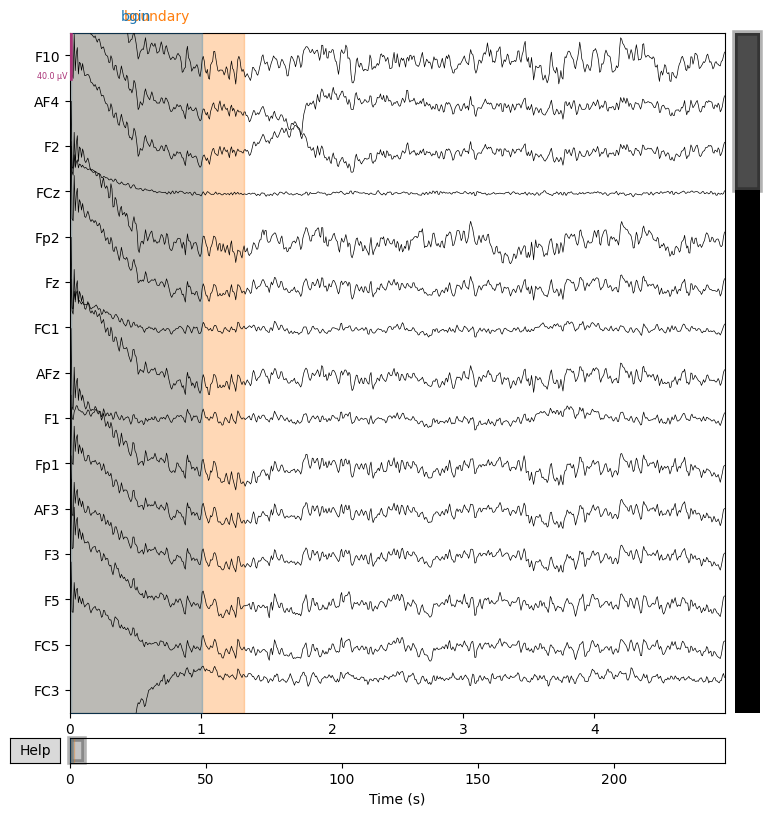


BRAINWAVE BAND ANALYSIS
Effective window size : 8.192 (s)


,Band,Power
0,Delta (0.5-4 Hz),2.527740e-11
1,Theta (4-8 Hz),1.829535e-12
2,Alpha (8-13 Hz),1.357254e-12
3,Beta (13-30 Hz),7.892011e-13
4,Gamma (30-45 Hz),3.107874e-13


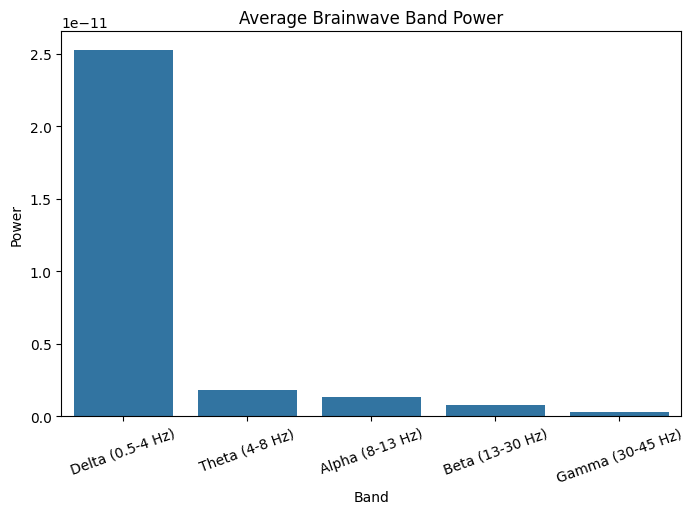


CHANNEL CORRELATION


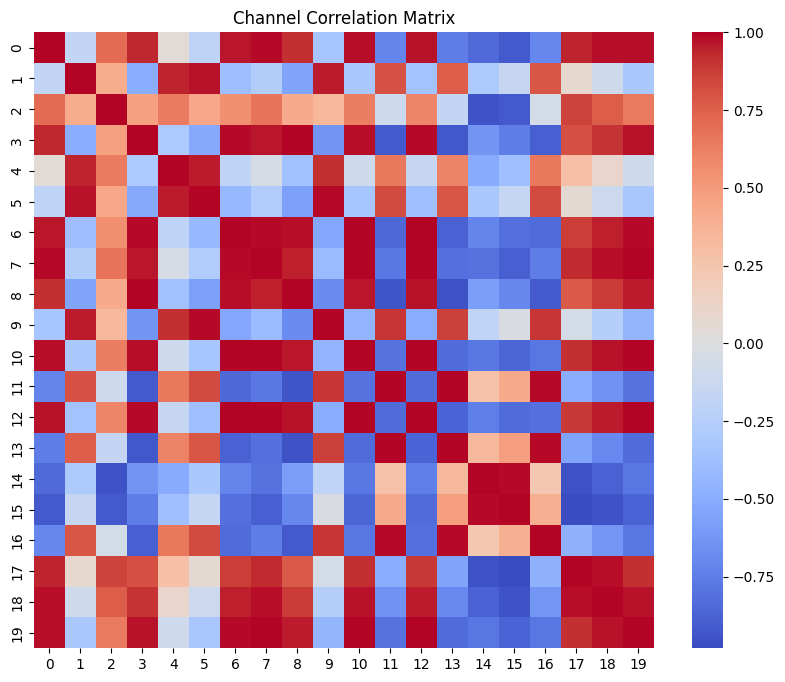


DATA QUALITY REPORT


,Metric,Value
0,Total Channels,65.000
1,Sampling Frequency,250.000
2,Recording Duration (sec),240.944
3,NaN Values,0.000
4,Infinite Values,0.000
5,Dead Channels,1.000



EDA Summary Saved To:
/kaggle/working/eeg_eda_summary.csv

EDA COMPLETED

This EDA analyzed:

1. Dataset Structure
2. EEG File Discovery
3. Subject Statistics
4. EEG Metadata
5. Channel Statistics
6. Missing Values
7. Dead Channels
8. Signal Visualization
9. Power Spectral Density
10. Sensor Layout
11. Event Distribution
12. Filtering
13. Brainwave Bands
14. Channel Correlation
15. Data Quality

Next Steps:
- Preprocessing
- Artifact Removal
- Epoch Extraction
- Feature Engineering
- Deep Learning
- Classification / Regression



In [27]:
# ============================================================
# FULL EEG EDA PIPELINE FOR OPENNEURO / BIDS DATASETS
# ============================================================
# Author: Sajid
# Platform: Kaggle
# Purpose:
#     Comprehensive Exploratory Data Analysis (EDA)
#     for EEG datasets (.edf/.vhdr/.set/.fif)
# ============================================================

# ============================================================
# 1. INSTALL LIBRARIES
# ============================================================

!pip install -q mne mne-bids pybv seaborn

# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import os
import glob
import json
import warnings
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import mne

from collections import Counter

warnings.filterwarnings("ignore")

# ============================================================
# 3. DATASET PATH
# ============================================================

DATASET_PATH = "/kaggle/input/datasets/sajidshahriar72543/ds007526-1-0-1/ds007526-1.0.1"

# ============================================================
# 4. EXPLORE DIRECTORY STRUCTURE
# ============================================================

print("="*60)
print("DATASET DIRECTORY STRUCTURE")
print("="*60)

for root, dirs, files in os.walk(DATASET_PATH):

    level = root.replace(DATASET_PATH, '').count(os.sep)
    indent = ' ' * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    subindent = ' ' * 4 * (level + 1)

    for f in files[:5]:
        print(f"{subindent}{f}")

# ============================================================
# 5. FIND ALL EEG FILES
# ============================================================

print("\n" + "="*60)
print("SEARCHING EEG FILES")
print("="*60)

extensions = ["*.edf", "*.vhdr", "*.set", "*.fif"]

eeg_files = []

for ext in extensions:
    eeg_files.extend(
        glob.glob(
            os.path.join(DATASET_PATH, "**", ext),
            recursive=True
        )
    )

print(f"\nTotal EEG Files Found: {len(eeg_files)}")

print("\nFirst 10 EEG Files:\n")

for f in eeg_files[:10]:
    print(f)

# ============================================================
# 6. SUBJECT ANALYSIS
# ============================================================

print("\n" + "="*60)
print("SUBJECT ANALYSIS")
print("="*60)

subjects = []

for path in eeg_files:

    parts = path.split(os.sep)

    for p in parts:
        if p.startswith("sub-"):
            subjects.append(p)

subject_counter = Counter(subjects)

print(f"\nTotal Subjects: {len(subject_counter)}")

subject_df = pd.DataFrame(
    subject_counter.items(),
    columns=["Subject", "Files"]
)

display(subject_df.head())

# Plot subject distribution

plt.figure(figsize=(12,5))

sns.barplot(
    x=subject_df["Subject"],
    y=subject_df["Files"]
)

plt.xticks(rotation=90)

plt.title("Files per Subject")

plt.show()

# ============================================================
# 7. LOAD EEG FILE FUNCTION
# ============================================================

print("\n" + "="*60)
print("LOADING EEG")
print("="*60)

def load_eeg(filepath):

    if filepath.endswith(".edf"):
        raw = mne.io.read_raw_edf(filepath, preload=True)

    elif filepath.endswith(".vhdr"):
        raw = mne.io.read_raw_brainvision(filepath, preload=True)

    elif filepath.endswith(".set"):
        raw = mne.io.read_raw_eeglab(filepath, preload=True)

    elif filepath.endswith(".fif"):
        raw = mne.io.read_raw_fif(filepath, preload=True)

    else:
        raise ValueError("Unsupported EEG format")

    return raw

# ============================================================
# 8. LOAD SAMPLE FILE
# ============================================================

sample_file = eeg_files[0]

print("\nSample File:\n")
print(sample_file)

raw = load_eeg(sample_file)

print("\nEEG Loaded Successfully")

# ============================================================
# 9. BASIC RECORDING INFORMATION
# ============================================================

print("\n" + "="*60)
print("BASIC EEG INFORMATION")
print("="*60)

print(raw)

print("\nSampling Frequency:")
print(raw.info["sfreq"])

print("\nNumber of Channels:")
print(len(raw.ch_names))

print("\nRecording Duration (sec):")
print(raw.times[-1])

print("\nChannel Names:")
print(raw.ch_names)

# ============================================================
# 10. CHANNEL TYPE ANALYSIS
# ============================================================

print("\n" + "="*60)
print("CHANNEL TYPE ANALYSIS")
print("="*60)

channel_types = Counter(
    mne.channel_type(raw.info, idx)
    for idx in range(len(raw.ch_names))
)

print(channel_types)

plt.figure(figsize=(6,4))

plt.bar(
    list(channel_types.keys()),
    list(channel_types.values())
)

plt.title("Channel Type Distribution")

plt.show()

# ============================================================
# 11. CHANNEL STATISTICS
# ============================================================

print("\n" + "="*60)
print("CHANNEL STATISTICS")
print("="*60)

data = raw.get_data()

channel_stats = pd.DataFrame({
    "Channel": raw.ch_names,
    "Mean": np.mean(data, axis=1),
    "STD": np.std(data, axis=1),
    "Min": np.min(data, axis=1),
    "Max": np.max(data, axis=1)
})

display(channel_stats.head())

# ============================================================
# 12. DETECT FLAT / DEAD CHANNELS
# ============================================================

print("\n" + "="*60)
print("DEAD CHANNEL DETECTION")
print("="*60)

dead_channels = channel_stats[
    channel_stats["STD"] < 1e-12
]

print(f"\nDead Channels Found: {len(dead_channels)}")

display(dead_channels)

# ============================================================
# 13. MISSING VALUE ANALYSIS
# ============================================================

print("\n" + "="*60)
print("MISSING VALUE ANALYSIS")
print("="*60)

print("NaN Values:", np.isnan(data).sum())

print("Infinite Values:", np.isinf(data).sum())

# ============================================================
# 14. EEG SIGNAL VISUALIZATION
# ============================================================

print("\n" + "="*60)
print("RAW EEG VISUALIZATION")
print("="*60)

raw.plot(
    duration=10,
    n_channels=15,
    scalings='auto'
)

# ============================================================
# 15. SINGLE CHANNEL VISUALIZATION
# ============================================================

print("\n" + "="*60)
print("SINGLE CHANNEL PLOT")
print("="*60)

channel_idx = 0

signal, times = raw[channel_idx, :5000]

plt.figure(figsize=(15,4))

plt.plot(times, signal[0])

plt.title(f"Signal of Channel: {raw.ch_names[channel_idx]}")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.grid(True)

plt.show()

# ============================================================
# 16. POWER SPECTRAL DENSITY
# ============================================================

print("\n" + "="*60)
print("POWER SPECTRAL DENSITY")
print("="*60)

raw.compute_psd().plot()

# ============================================================
# 17. SENSOR TOPOGRAPHY
# ============================================================

print("\n" + "="*60)
print("SENSOR LAYOUT")
print("="*60)

raw.plot_sensors(show_names=True)

# ============================================================
# 18. EVENT / ANNOTATION ANALYSIS
# ============================================================

print("\n" + "="*60)
print("EVENT ANALYSIS")
print("="*60)

try:

    events, event_dict = mne.events_from_annotations(raw)

    print("\nEvent Dictionary:")
    print(event_dict)

    print("\nTotal Events:")
    print(len(events))

    reverse_dict = {v:k for k,v in event_dict.items()}

    event_names = []

    for e in events[:,2]:
        event_names.append(reverse_dict[e])

    event_counts = pd.Series(event_names).value_counts()

    display(event_counts)

    plt.figure(figsize=(10,5))

    sns.barplot(
        x=event_counts.index,
        y=event_counts.values
    )

    plt.xticks(rotation=90)

    plt.title("Event Distribution")

    plt.show()

except Exception as e:

    print("\nNo Events Found")
    print(e)

# ============================================================
# 19. FILTERING ANALYSIS
# ============================================================

print("\n" + "="*60)
print("FILTERED EEG")
print("="*60)

filtered = raw.copy().filter(
    l_freq=1,
    h_freq=40
)

filtered.plot(
    duration=5,
    n_channels=15
)

# ============================================================
# 20. BAND POWER ANALYSIS
# ============================================================

print("\n" + "="*60)
print("BRAINWAVE BAND ANALYSIS")
print("="*60)

bands = {
    "Delta (0.5-4 Hz)": (0.5, 4),
    "Theta (4-8 Hz)": (4, 8),
    "Alpha (8-13 Hz)": (8, 13),
    "Beta (13-30 Hz)": (13, 30),
    "Gamma (30-45 Hz)": (30, 45)
}

psd = raw.compute_psd()

freqs = psd.freqs
psds = psd.get_data()

band_powers = {}

for band_name, (fmin, fmax) in bands.items():

    idx = np.logical_and(freqs >= fmin, freqs <= fmax)

    band_power = psds[:, idx].mean()

    band_powers[band_name] = band_power

band_df = pd.DataFrame({
    "Band": list(band_powers.keys()),
    "Power": list(band_powers.values())
})

display(band_df)

plt.figure(figsize=(8,5))

sns.barplot(
    x="Band",
    y="Power",
    data=band_df
)

plt.title("Average Brainwave Band Power")

plt.xticks(rotation=20)

plt.show()

# ============================================================
# 21. CORRELATION BETWEEN CHANNELS
# ============================================================

print("\n" + "="*60)
print("CHANNEL CORRELATION")
print("="*60)

subset = data[:20, :5000]

corr_matrix = np.corrcoef(subset)

plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm"
)

plt.title("Channel Correlation Matrix")

plt.show()

# ============================================================
# 22. DATA QUALITY REPORT
# ============================================================

print("\n" + "="*60)
print("DATA QUALITY REPORT")
print("="*60)

quality_report = {
    "Total Channels": len(raw.ch_names),
    "Sampling Frequency": raw.info["sfreq"],
    "Recording Duration (sec)": raw.times[-1],
    "NaN Values": int(np.isnan(data).sum()),
    "Infinite Values": int(np.isinf(data).sum()),
    "Dead Channels": len(dead_channels)
}

quality_df = pd.DataFrame(
    quality_report.items(),
    columns=["Metric", "Value"]
)

display(quality_df)

# ============================================================
# 23. SAVE SUMMARY
# ============================================================

summary_path = "/kaggle/working/eeg_eda_summary.csv"

quality_df.to_csv(summary_path, index=False)

print("\nEDA Summary Saved To:")
print(summary_path)

# ============================================================
# 24. FINAL NOTES
# ============================================================

print("\n" + "="*60)
print("EDA COMPLETED")
print("="*60)

print("""
This EDA analyzed:

1. Dataset Structure
2. EEG File Discovery
3. Subject Statistics
4. EEG Metadata
5. Channel Statistics
6. Missing Values
7. Dead Channels
8. Signal Visualization
9. Power Spectral Density
10. Sensor Layout
11. Event Distribution
12. Filtering
13. Brainwave Bands
14. Channel Correlation
15. Data Quality

Next Steps:
- Preprocessing
- Artifact Removal
- Epoch Extraction
- Feature Engineering
- Deep Learning
- Classification / Regression
""")

In [28]:
try:

    events, event_dict = mne.events_from_annotations(raw)

    print("Event Dictionary:\n")
    print(event_dict)

    print("\nTotal Events:")
    print(len(events))

except Exception as e:

    print("No events found.")
    print(e)

Used Annotations descriptions: [np.str_('bgin'), np.str_('boundary')]
Event Dictionary:

{np.str_('bgin'): 1, np.str_('boundary'): 2}

Total Events:
2


boundary    1
bgin        1
Name: count, dtype: int64


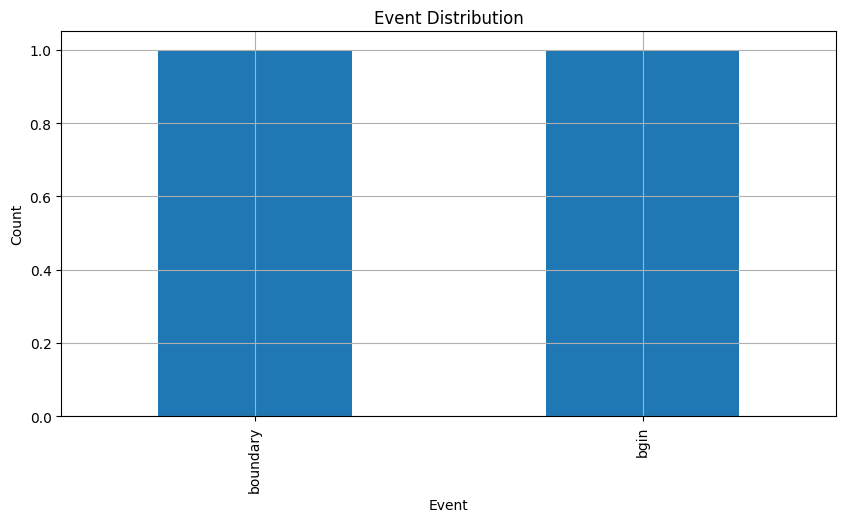

In [29]:
reverse_dict = {v:k for k,v in event_dict.items()}

event_names = []

for e in events[:,2]:
    event_names.append(reverse_dict[e])

event_counts = pd.Series(event_names).value_counts()

print(event_counts)

plt.figure(figsize=(10,5))

event_counts.plot(kind="bar")

plt.title("Event Distribution")

plt.xlabel("Event")

plt.ylabel("Count")

plt.grid(True)

plt.show()

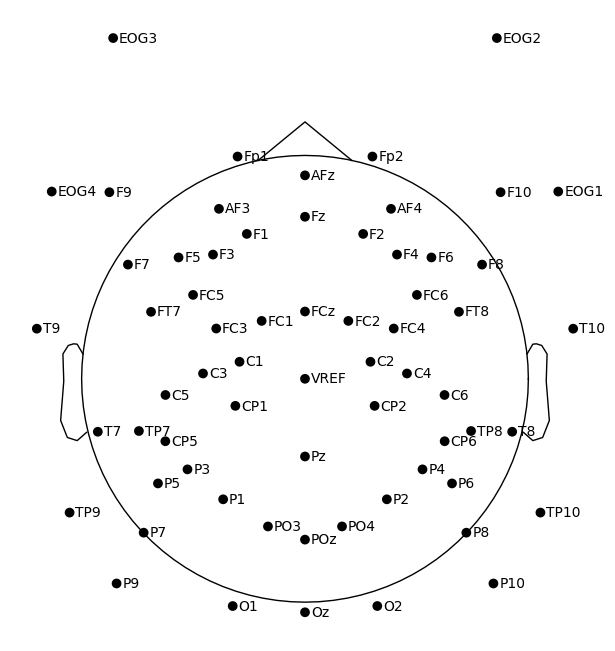

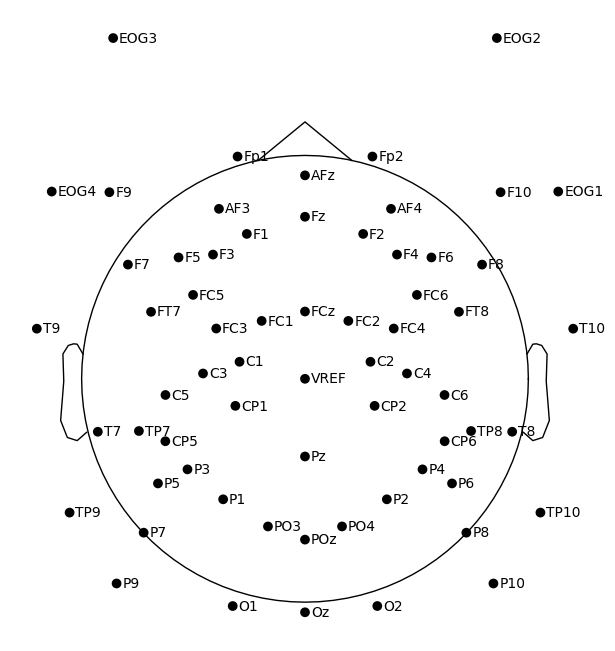

In [30]:
raw.plot_sensors(show_names=True)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 825 samples (3.300 s)



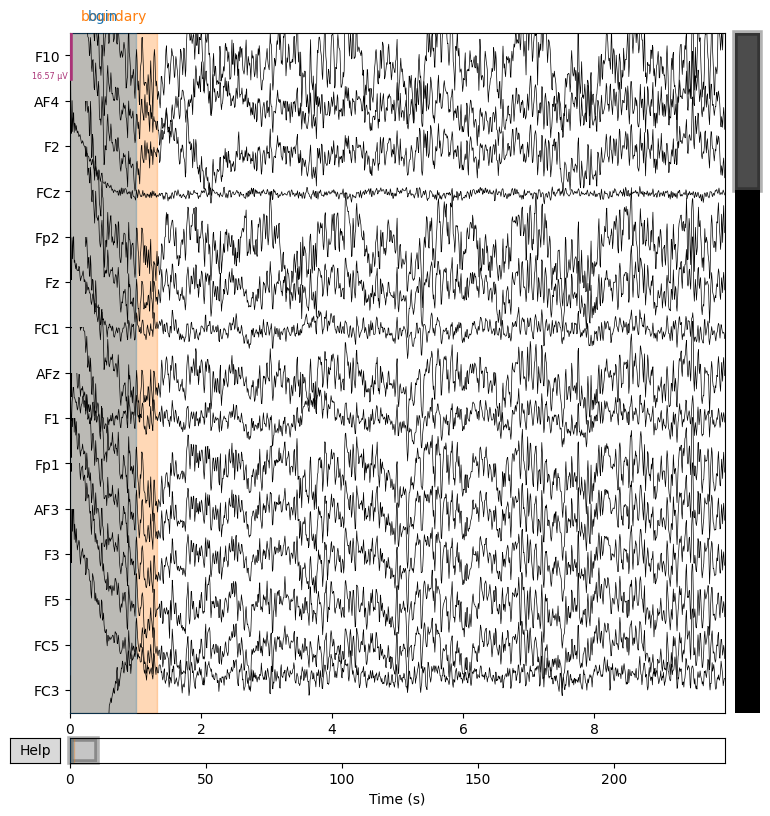

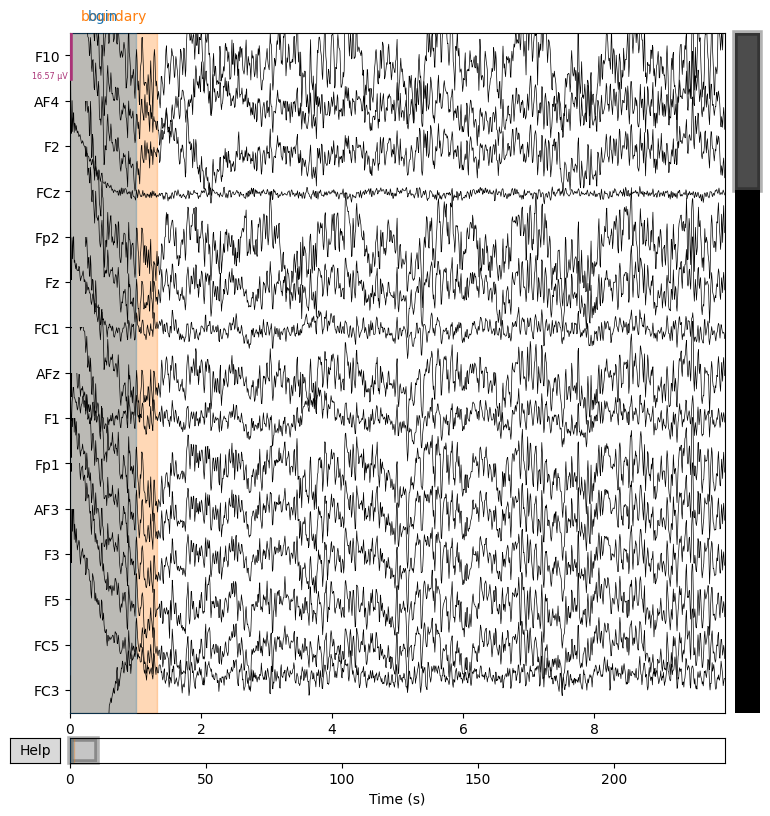

In [31]:
filtered = raw.copy().filter(1, 40)

filtered.plot(
    duration=10,
    n_channels=15,
    scalings='auto'
)

Effective window size : 8.192 (s)
    Band         Power
0  Delta  2.527740e-11
1  Theta  1.829535e-12
2  Alpha  1.357254e-12
3   Beta  7.892011e-13
4  Gamma  3.107874e-13


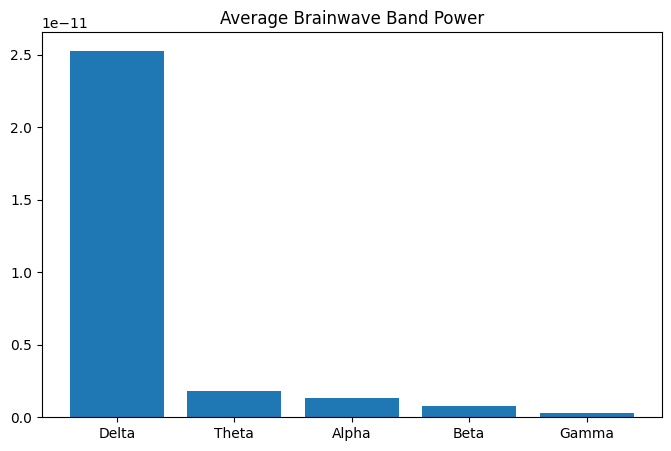

In [32]:
bands = {
    "Delta": (0.5, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
    "Gamma": (30, 45)
}

psd = raw.compute_psd()

freqs = psd.freqs
psds = psd.get_data()

band_powers = {}

for band_name, (fmin, fmax) in bands.items():

    idx = np.logical_and(freqs >= fmin, freqs <= fmax)

    band_power = psds[:, idx].mean()

    band_powers[band_name] = band_power

band_df = pd.DataFrame({
    "Band": list(band_powers.keys()),
    "Power": list(band_powers.values())
})

print(band_df)

plt.figure(figsize=(8,5))

plt.bar(
    band_df["Band"],
    band_df["Power"]
)

plt.title("Average Brainwave Band Power")

plt.show()

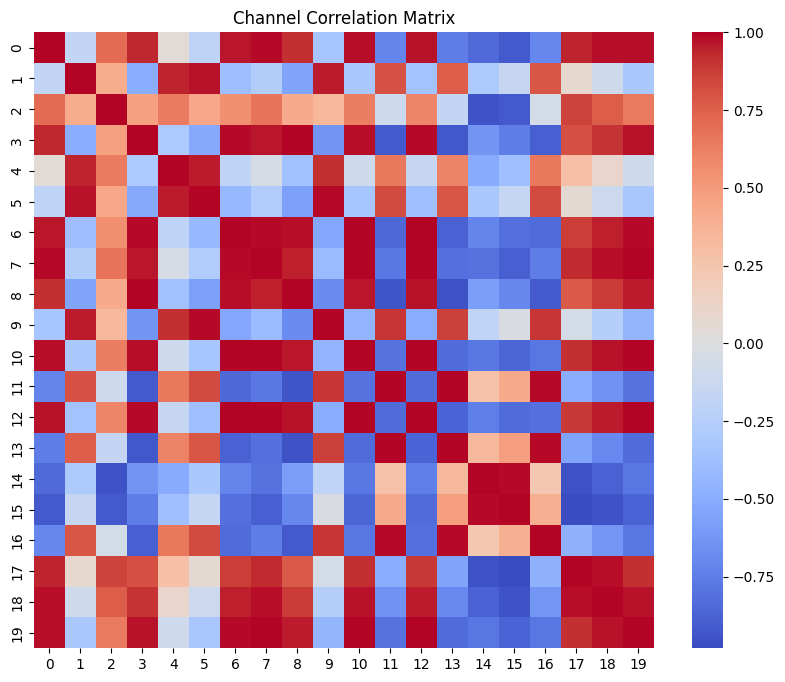

In [33]:
subset = data[:20, :5000]

corr_matrix = np.corrcoef(subset)

plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm"
)

plt.title("Channel Correlation Matrix")

plt.show()

In [34]:
summary = []

for file in eeg_files[:10]:

    try:

        raw_tmp = load_eeg(file)

        summary.append({
            "file": os.path.basename(file),
            "channels": len(raw_tmp.ch_names),
            "sfreq": raw_tmp.info["sfreq"],
            "duration_sec": raw_tmp.times[-1]
        })

    except Exception as e:

        summary.append({
            "file": os.path.basename(file),
            "error": str(e)
        })

summary_df = pd.DataFrame(summary)

summary_df

,file,channels,sfreq,duration_sec
0,sub-093_task-rest_eeg.set,65,250.0,240.944
1,sub-093_task-walk_eeg.set,65,250.0,240.920
2,sub-128_task-walk_eeg.set,65,250.0,241.036
3,sub-128_task-rest_eeg.set,65,250.0,240.968
4,sub-060_task-rest_eeg.set,65,250.0,243.632
5,sub-060_task-walk_eeg.set,65,250.0,243.628
6,sub-137_task-rest_eeg.set,65,250.0,240.916
7,sub-137_task-walk_eeg.set,65,250.0,240.988
8,sub-121_task-walk_eeg.set,65,250.0,240.944
9,sub-121_task-rest_eeg.set,65,250.0,242.400


In [35]:
full_summary = []

for file in eeg_files:

    try:

        raw_tmp = load_eeg(file)

        full_summary.append({
            "file": os.path.basename(file),
            "channels": len(raw_tmp.ch_names),
            "sfreq": raw_tmp.info["sfreq"],
            "duration_sec": raw_tmp.times[-1],
            "status": "OK"
        })

    except Exception as e:

        full_summary.append({
            "file": os.path.basename(file),
            "status": "ERROR",
            "error": str(e)
        })

summary_df = pd.DataFrame(full_summary)

summary_df.head()

,file,channels,sfreq,duration_sec,status
0,sub-093_task-rest_eeg.set,65,250.0,240.944,OK
1,sub-093_task-walk_eeg.set,65,250.0,240.920,OK
2,sub-128_task-walk_eeg.set,65,250.0,241.036,OK
3,sub-128_task-rest_eeg.set,65,250.0,240.968,OK
4,sub-060_task-rest_eeg.set,65,250.0,243.632,OK


In [36]:
errors_df = summary_df[
    summary_df["status"] == "ERROR"
]

print("Corrupted Files:", len(errors_df))

errors_df.head()

Corrupted Files: 0


,file,channels,sfreq,duration_sec,status


In [37]:
summary_df["sfreq"].value_counts()

sfreq
250.0    277
Name: count, dtype: int64

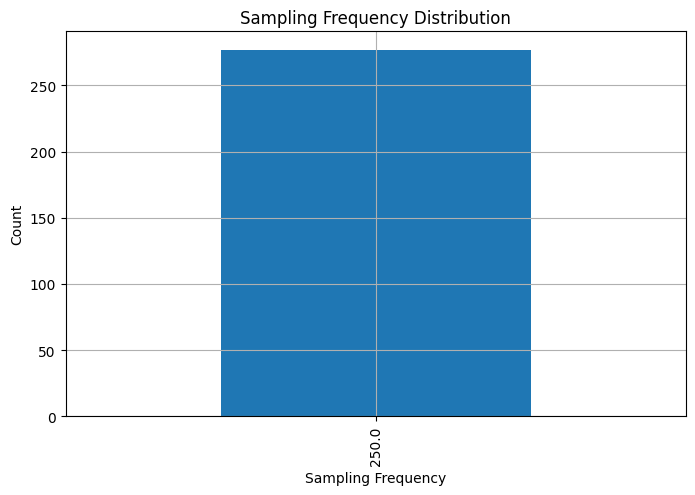

In [38]:
plt.figure(figsize=(8,5))

summary_df["sfreq"].value_counts().plot(kind="bar")

plt.title("Sampling Frequency Distribution")

plt.xlabel("Sampling Frequency")

plt.ylabel("Count")

plt.grid(True)

plt.show()

In [39]:
summary_df["channels"].value_counts()

channels
65    277
Name: count, dtype: int64

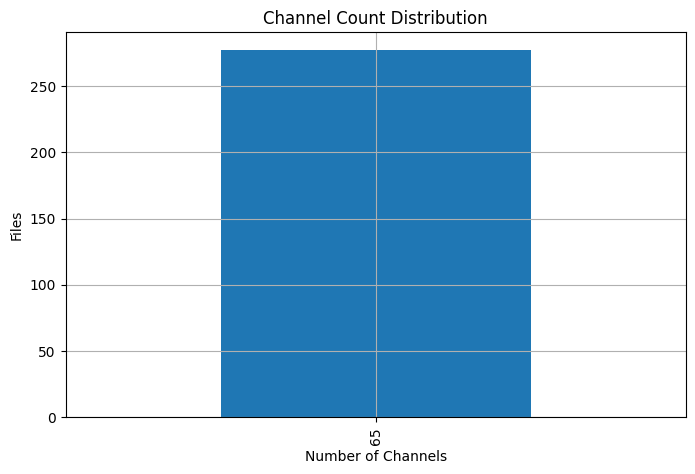

In [40]:
plt.figure(figsize=(8,5))

summary_df["channels"].value_counts().plot(kind="bar")

plt.title("Channel Count Distribution")

plt.xlabel("Number of Channels")

plt.ylabel("Files")

plt.grid(True)

plt.show()

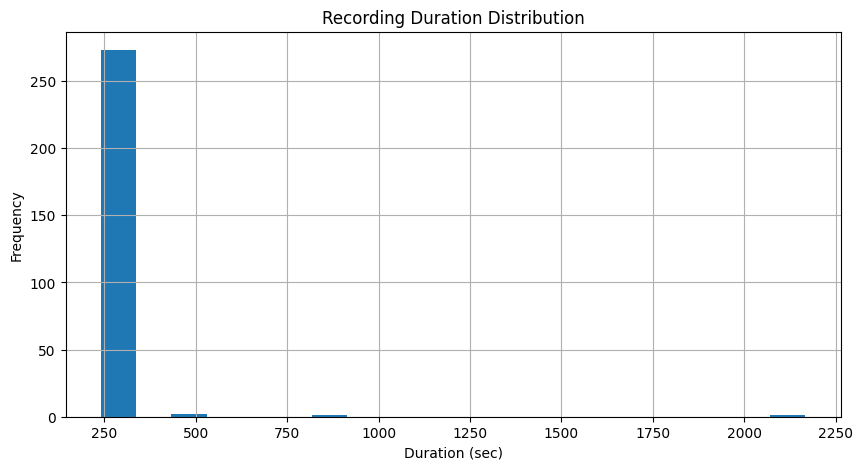

In [41]:
plt.figure(figsize=(10,5))

summary_df["duration_sec"].hist(
    bins=20
)

plt.title("Recording Duration Distribution")

plt.xlabel("Duration (sec)")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

In [42]:
bad_channel_report = []

for file in eeg_files[:20]:

    try:

        raw_tmp = load_eeg(file)

        data_tmp = raw_tmp.get_data()

        stds = np.std(data_tmp, axis=1)

        dead = np.sum(stds < 1e-12)

        bad_channel_report.append({
            "file": os.path.basename(file),
            "dead_channels": dead
        })

    except:
        pass

bad_df = pd.DataFrame(bad_channel_report)

bad_df

,file,dead_channels
0,sub-093_task-rest_eeg.set,1
1,sub-093_task-walk_eeg.set,1
2,sub-128_task-walk_eeg.set,1
3,sub-128_task-rest_eeg.set,1
4,sub-060_task-rest_eeg.set,1
5,sub-060_task-walk_eeg.set,2
6,sub-137_task-rest_eeg.set,1
7,sub-137_task-walk_eeg.set,1
8,sub-121_task-walk_eeg.set,1
9,sub-121_task-rest_eeg.set,2


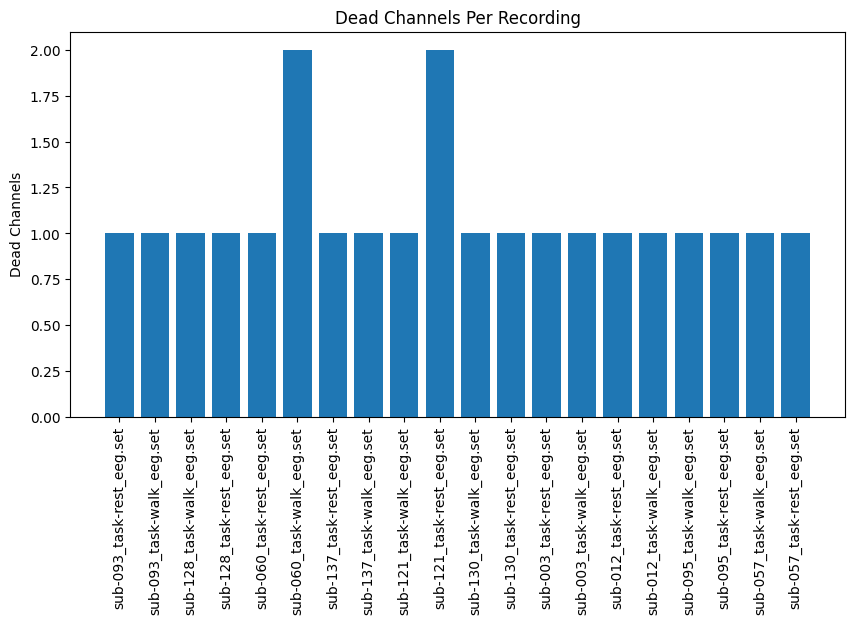

In [43]:
plt.figure(figsize=(10,5))

plt.bar(
    bad_df["file"],
    bad_df["dead_channels"]
)

plt.xticks(rotation=90)

plt.title("Dead Channels Per Recording")

plt.ylabel("Dead Channels")

plt.show()

In [44]:
all_bandpowers = []

bands = {
    "Delta": (0.5, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
    "Gamma": (30, 45)
}

for file in eeg_files[:10]:

    try:

        raw_tmp = load_eeg(file)

        psd = raw_tmp.compute_psd()

        freqs = psd.freqs
        psds = psd.get_data()

        result = {
            "file": os.path.basename(file)
        }

        for band_name, (fmin, fmax) in bands.items():

            idx = np.logical_and(
                freqs >= fmin,
                freqs <= fmax
            )

            result[band_name] = psds[:, idx].mean()

        all_bandpowers.append(result)

    except:
        pass

bandpower_df = pd.DataFrame(all_bandpowers)

bandpower_df.head()

Effective window size : 8.192 (s)
Effective window size : 8.192 (s)
Effective window size : 8.192 (s)
Effective window size : 8.192 (s)
Effective window size : 8.192 (s)
Effective window size : 8.192 (s)
Effective window size : 8.192 (s)
Effective window size : 8.192 (s)
Effective window size : 8.192 (s)
Effective window size : 8.192 (s)


,file,Delta,Theta,Alpha,Beta,Gamma
0,sub-093_task-rest_eeg.set,2.527740e-11,1.829535e-12,1.357254e-12,7.892011e-13,3.107874e-13
1,sub-093_task-walk_eeg.set,2.855444e-11,6.673963e-12,2.783184e-12,1.367586e-12,7.011014e-13
2,sub-128_task-walk_eeg.set,1.882342e-10,1.440662e-11,3.035240e-12,1.505213e-12,1.816347e-12
3,sub-128_task-rest_eeg.set,1.283569e-11,3.095840e-12,8.425048e-12,5.626655e-13,1.535736e-13
4,sub-060_task-rest_eeg.set,1.562139e-10,2.996278e-12,4.340698e-12,7.548533e-13,4.267844e-13


In [45]:
summary_df.to_csv(
    "/kaggle/working/eeg_recording_summary.csv",
    index=False
)

bandpower_df.to_csv(
    "/kaggle/working/eeg_bandpower_summary.csv",
    index=False
)

print("EDA reports saved.")

EDA reports saved.


In [46]:
bp_summary = pd.read_csv("/kaggle/working/eeg_bandpower_summary.csv")
bp_summary

,file,Delta,Theta,Alpha,Beta,Gamma
0,sub-093_task-rest_eeg.set,2.527740e-11,1.829535e-12,1.357254e-12,7.892011e-13,3.107874e-13
1,sub-093_task-walk_eeg.set,2.855444e-11,6.673963e-12,2.783184e-12,1.367586e-12,7.011014e-13
2,sub-128_task-walk_eeg.set,1.882342e-10,1.440662e-11,3.035240e-12,1.505213e-12,1.816347e-12
3,sub-128_task-rest_eeg.set,1.283569e-11,3.095840e-12,8.425048e-12,5.626655e-13,1.535736e-13
4,sub-060_task-rest_eeg.set,1.562139e-10,2.996278e-12,4.340698e-12,7.548533e-13,4.267844e-13
5,sub-060_task-walk_eeg.set,8.878814e-08,4.472688e-09,4.482753e-10,4.459445e-11,6.266623e-12
6,sub-137_task-rest_eeg.set,8.364959e-12,3.824513e-12,9.459973e-12,9.271689e-13,1.503581e-13
7,sub-137_task-walk_eeg.set,1.028999e-08,1.774304e-11,4.913616e-12,1.252758e-12,4.193792e-13
8,sub-121_task-walk_eeg.set,1.576757e-09,6.129745e-11,8.417617e-12,1.315060e-12,7.914536e-13
9,sub-121_task-rest_eeg.set,7.185319e-12,4.684697e-12,6.999509e-12,7.168389e-13,2.002165e-13


In [47]:
eda_summary = pd.read_csv("/kaggle/working/eeg_eda_summary.csv")
eda_summary

,Metric,Value
0,Total Channels,65.000
1,Sampling Frequency,250.000
2,Recording Duration (sec),240.944
3,NaN Values,0.000
4,Infinite Values,0.000
5,Dead Channels,1.000


In [48]:
rec_summary = pd.read_csv("/kaggle/working/eeg_recording_summary.csv")
rec_summary

,file,channels,sfreq,duration_sec,status
0,sub-093_task-rest_eeg.set,65,250.0,240.944,OK
1,sub-093_task-walk_eeg.set,65,250.0,240.920,OK
2,sub-128_task-walk_eeg.set,65,250.0,241.036,OK
3,sub-128_task-rest_eeg.set,65,250.0,240.968,OK
4,sub-060_task-rest_eeg.set,65,250.0,243.632,OK
...,...,...,...,...,...
272,sub-136_task-rest_eeg.set,65,250.0,240.924,OK
273,sub-037_task-walk_eeg.set,65,250.0,241.168,OK
274,sub-037_task-rest_eeg.set,65,250.0,243.608,OK
275,sub-096_task-walk_eeg.set,65,250.0,240.992,OK


# Preprocessing

In [49]:
channel_stats.sort_values("STD").head(10)

,Channel,Mean,STD,Min,Max
64,VREF,0.000000,0.000000,0.000000,0.000000
26,P5,-0.003473,0.000277,-0.004009,-0.003027
38,O2,0.001407,0.000523,0.000255,0.002475
5,Fz,0.011397,0.000560,0.010308,0.012521
35,POz,0.018230,0.000599,0.017054,0.019082
18,FT7,-0.018888,0.000660,-0.020548,-0.017737
17,F7,-0.015088,0.000680,-0.017069,-0.014329
45,CP6,0.008551,0.000742,0.006888,0.009427
22,T9,0.008572,0.000749,0.007127,0.009764
54,T10,-0.018877,0.000772,-0.020850,-0.016886


In [50]:
raw.drop_channels(["VREF"])

<RawEEGLAB | sub-093_task-rest_eeg.set, 64 x 60237 (240.9 s), ~29.5 MiB, data loaded>

In [51]:
data = raw.get_data()

channel_stats = pd.DataFrame({
    "Channel": raw.ch_names,
    "STD": np.std(data, axis=1)
})

channel_stats.sort_values("STD").head()

,Channel,STD
26,P5,0.000277
38,O2,0.000523
5,Fz,0.000560
35,POz,0.000599
18,FT7,0.000660


In [52]:
raw.set_channel_types({
    "EOG1": "eog",
    "EOG2": "eog",
    "EOG3": "eog",
    "EOG4": "eog"
})

<RawEEGLAB | sub-093_task-rest_eeg.set, 64 x 60237 (240.9 s), ~29.5 MiB, data loaded>

In [53]:
montage = mne.channels.make_standard_montage("standard_1020")

raw.set_montage(montage)

<RawEEGLAB | sub-093_task-rest_eeg.set, 64 x 60237 (240.9 s), ~29.5 MiB, data loaded>

In [54]:
print(raw.get_channel_types())

['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eog', 'eog', 'eog', 'eog']


In [55]:
filtered = raw.copy().filter(
    l_freq=1,
    h_freq=40
)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 825 samples (3.300 s)



In [56]:
filtered.notch_filter(freqs=50)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 1651 samples (6.604 s)



<RawEEGLAB | sub-093_task-rest_eeg.set, 64 x 60237 (240.9 s), ~29.5 MiB, data loaded>

In [57]:
ica = mne.preprocessing.ICA(
    n_components=20,
    random_state=42,
    max_iter="auto"
)

ica.fit(filtered)

Fitting ICA to data using 60 channels (please be patient, this may take a while)
Selecting by number: 20 components
Fitting ICA took 1.2s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,61 iterations on raw data (60237 samples)
ICA components,20
Available PCA components,60
Channel types,eeg
ICA components marked for exclusion,—


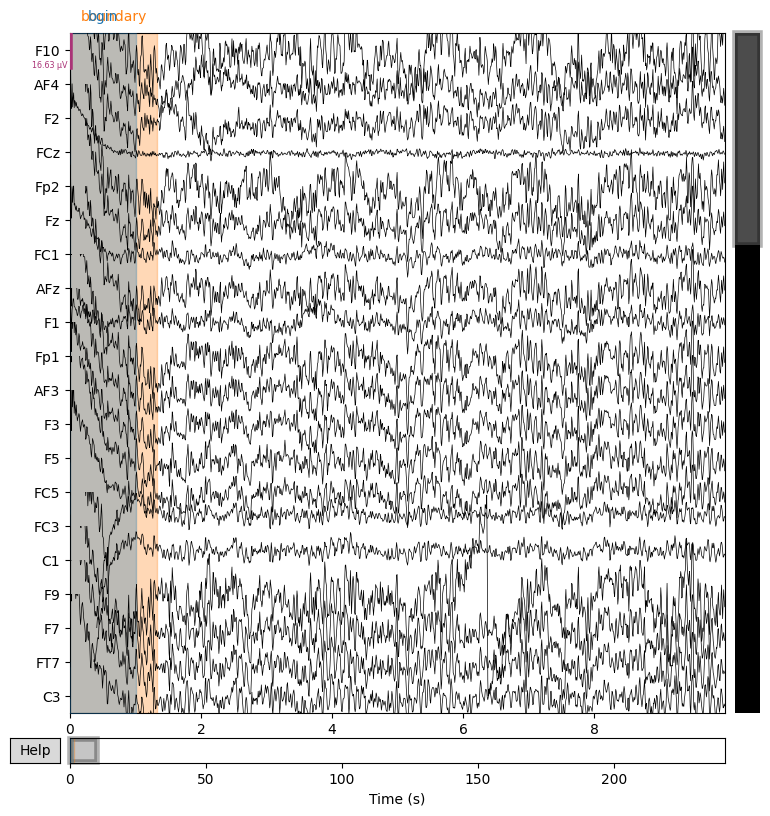

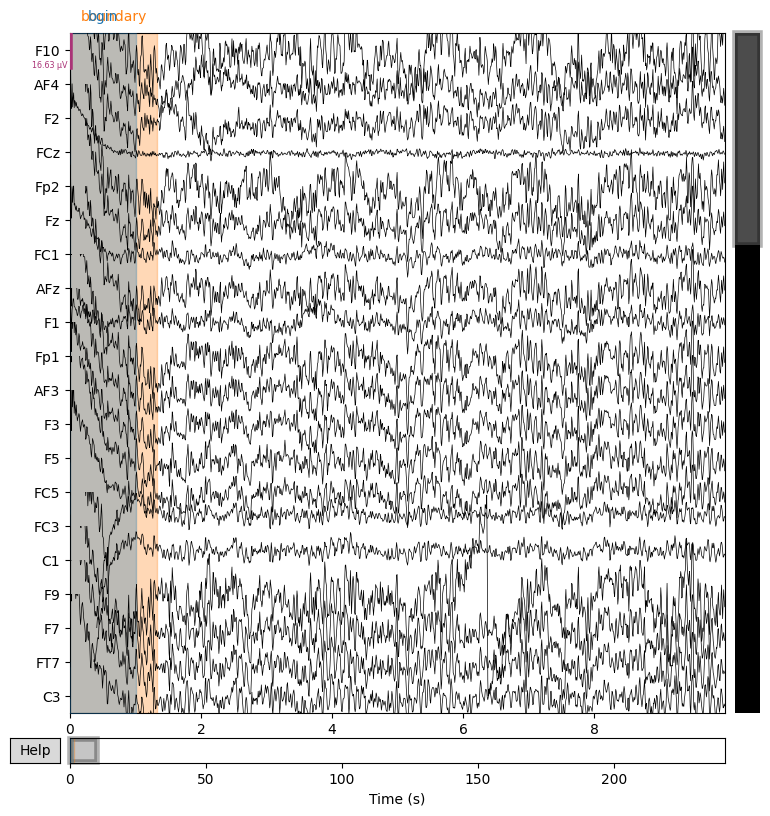

In [58]:
filtered.plot(
    duration=10,
    n_channels=20,
    scalings='auto'
)

In [59]:
ica = mne.preprocessing.ICA(
    n_components=20,
    random_state=42,
    max_iter="auto"
)

ica.fit(filtered)

Fitting ICA to data using 60 channels (please be patient, this may take a while)
Selecting by number: 20 components
Fitting ICA took 1.2s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,61 iterations on raw data (60237 samples)
ICA components,20
Available PCA components,60
Channel types,eeg
ICA components marked for exclusion,—


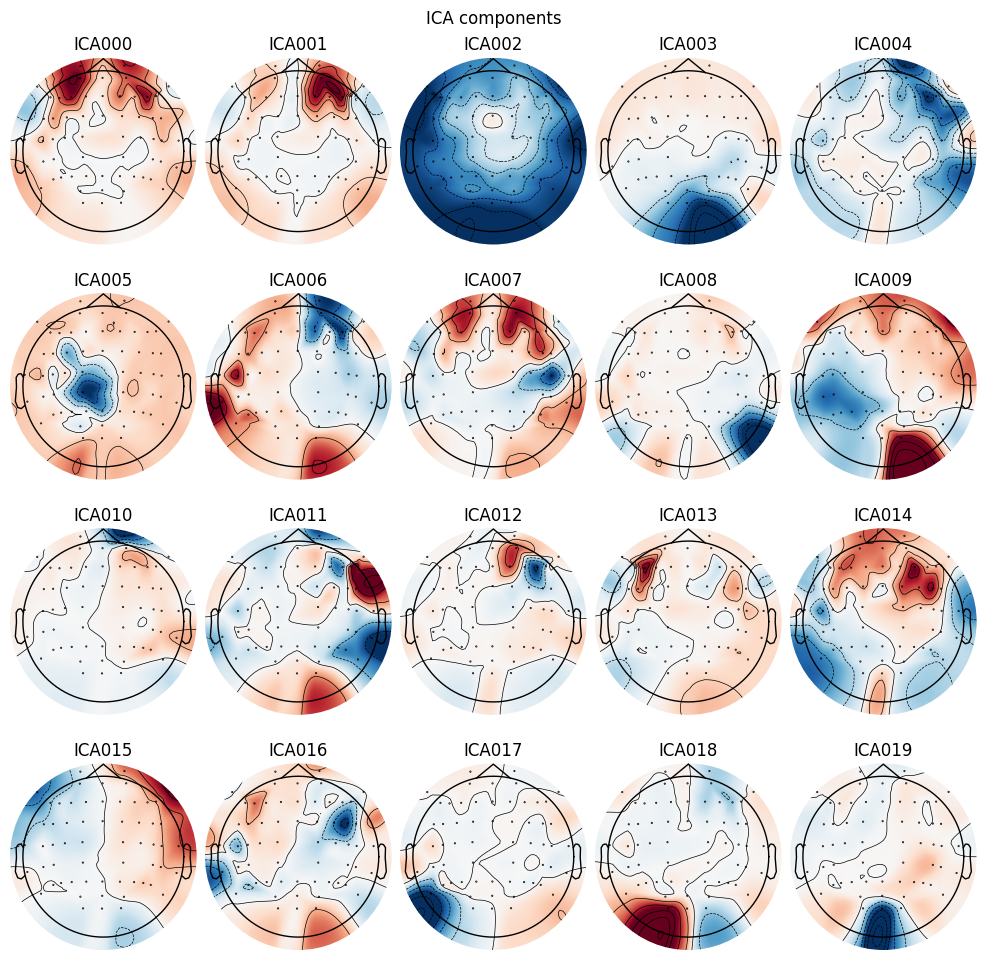

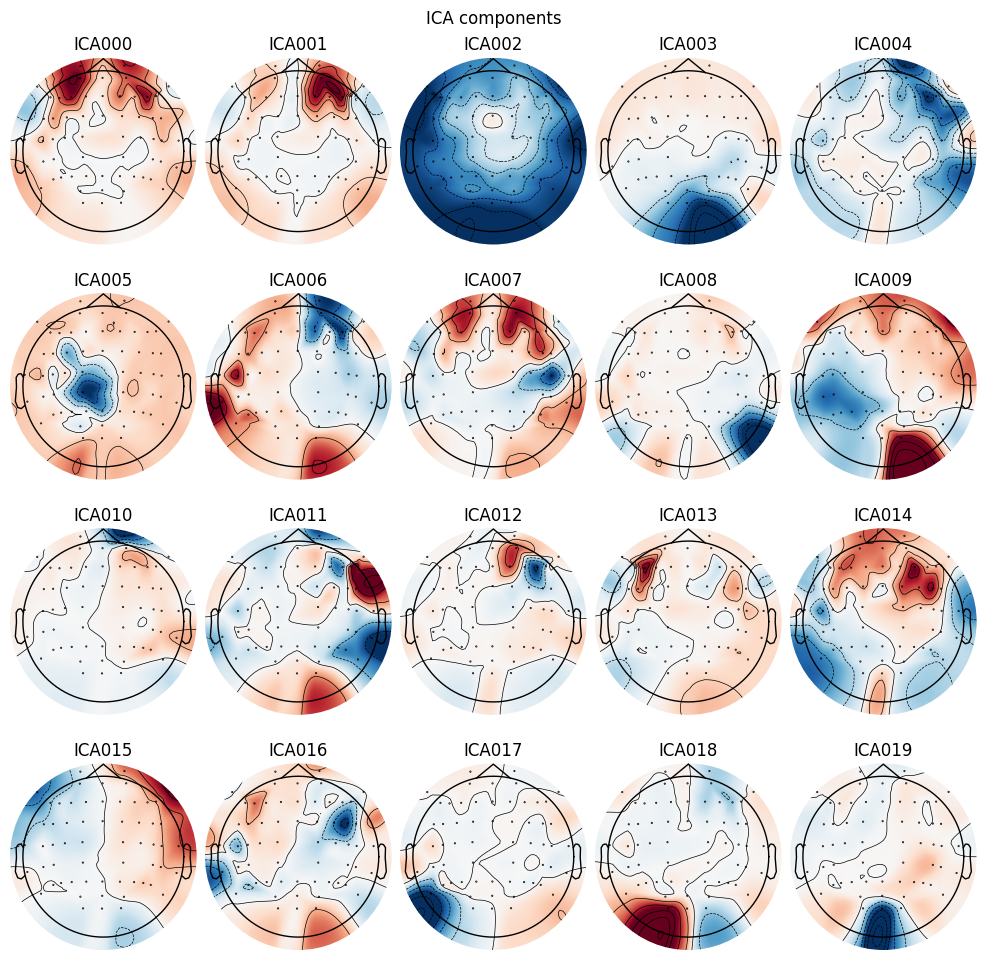

In [60]:
ica.plot_components()

Creating RawArray with float64 data, n_channels=24, n_times=60237
    Range : 0 ... 60236 =      0.000 ...   240.944 secs
Ready.


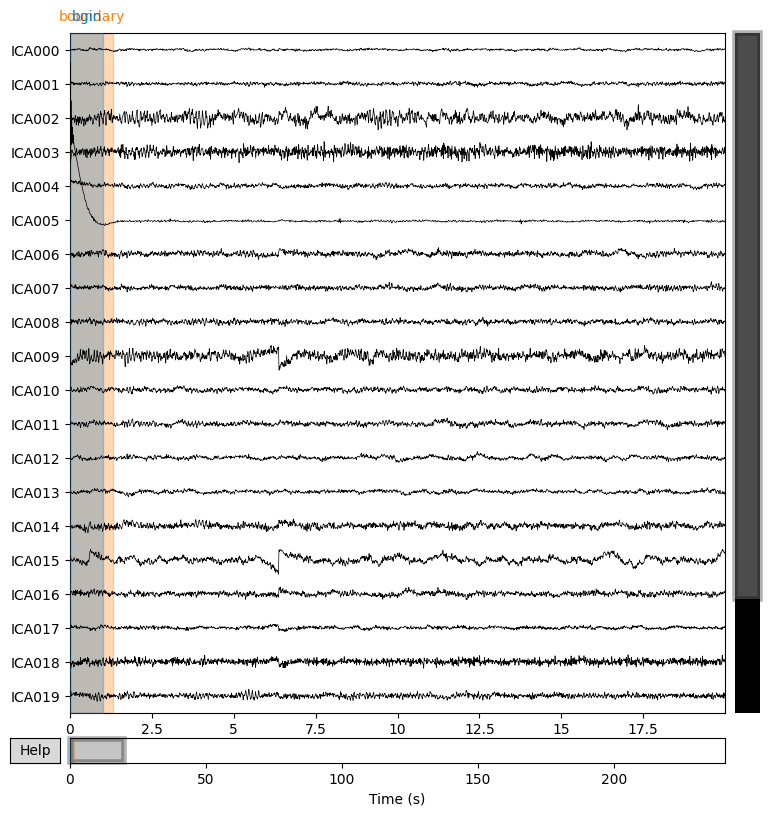

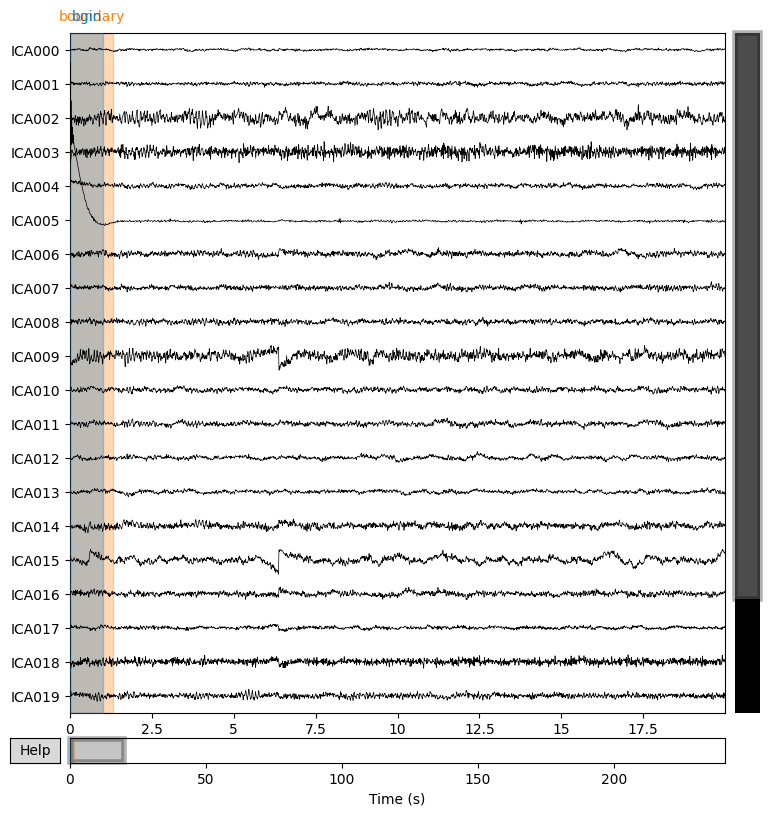

In [61]:
ica.plot_sources(filtered)

In [62]:
eog_indices, eog_scores = ica.find_bads_eog(
    filtered
)

print("Detected EOG Components:")
print(eog_indices)

Using EOG channels: EOG1, EOG2, EOG3, EOG4
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 2500 samples (10.000 s)

... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff fre

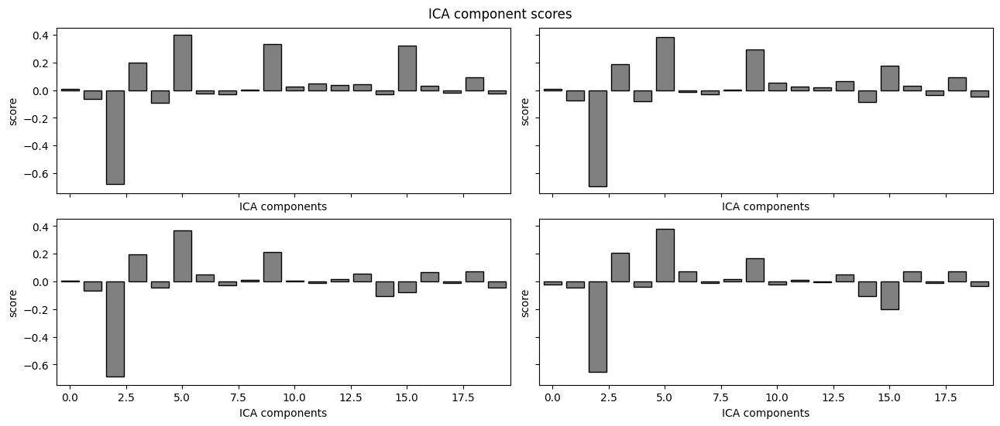

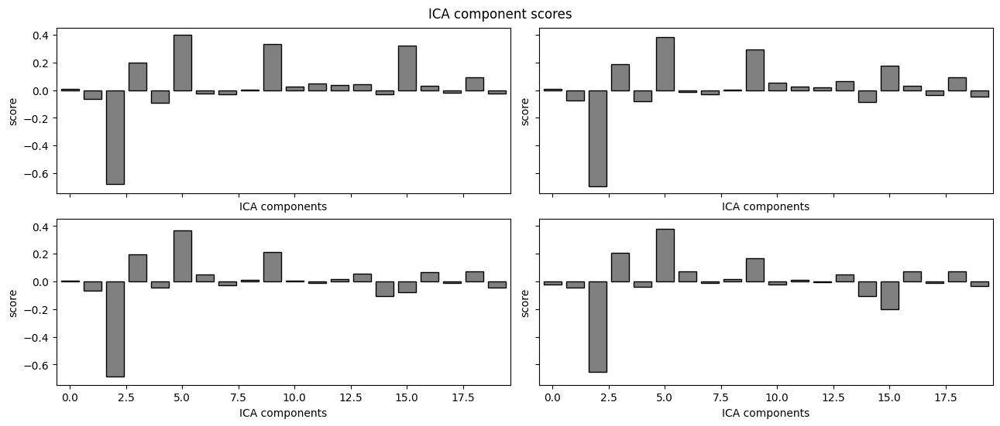

In [63]:
ica.plot_scores(eog_scores)

In [64]:
ica.exclude = eog_indices

In [65]:
cleaned = filtered.copy()

ica.apply(cleaned)

Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 60 PCA components


<RawEEGLAB | sub-093_task-rest_eeg.set, 64 x 60237 (240.9 s), ~29.5 MiB, data loaded>

ICA Before


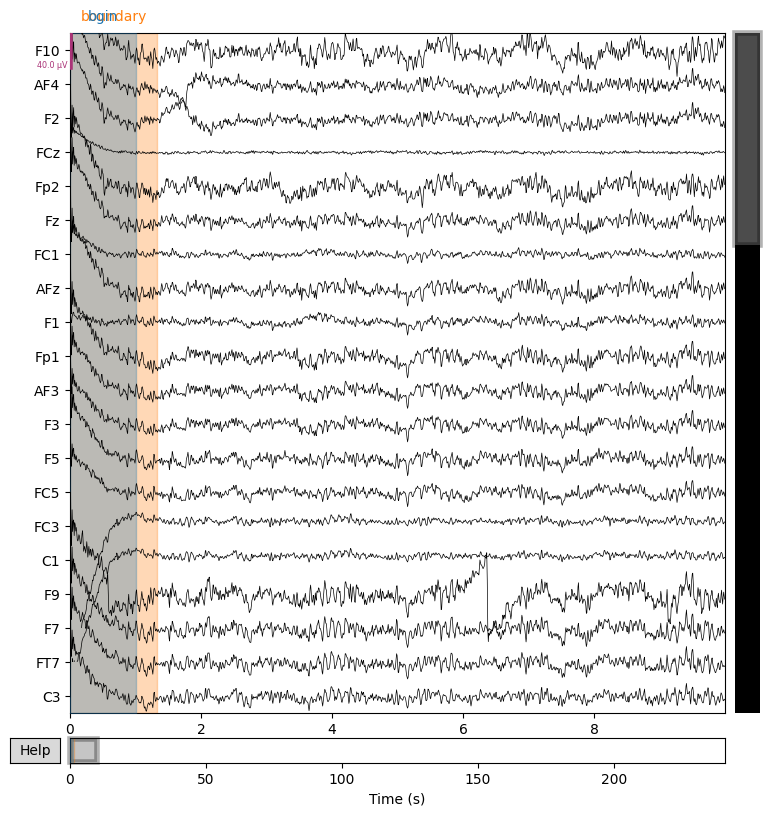

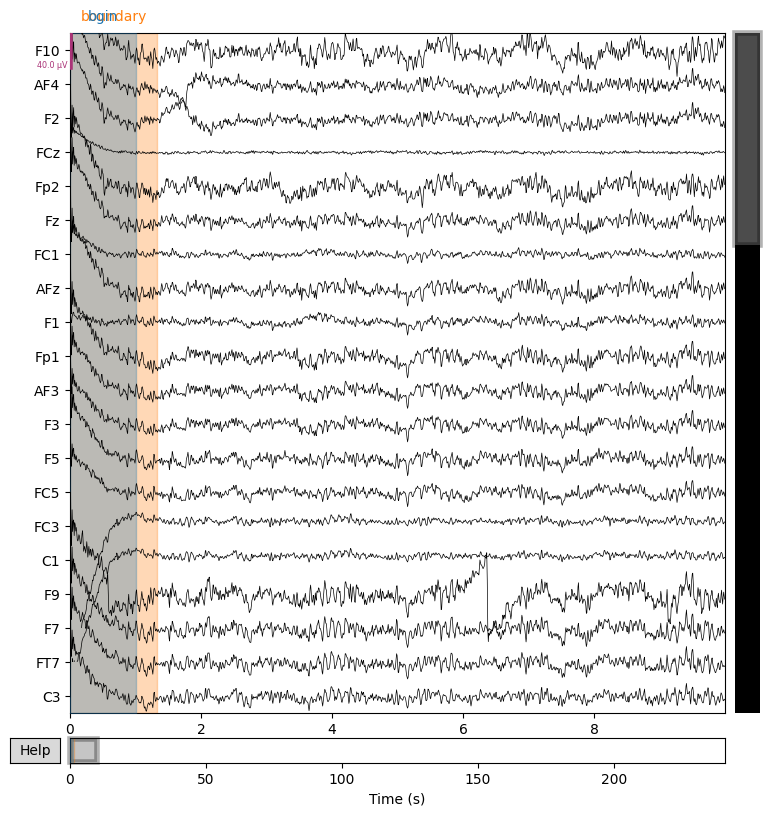

In [66]:
print("ICA Before")
filtered.plot(duration=10, n_channels=20)

ICA After


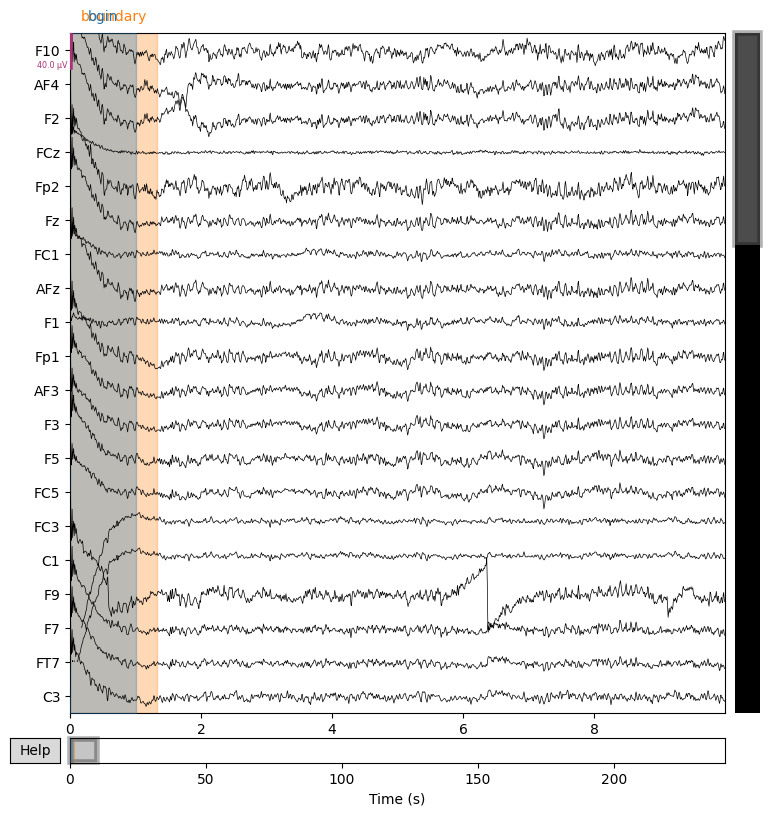

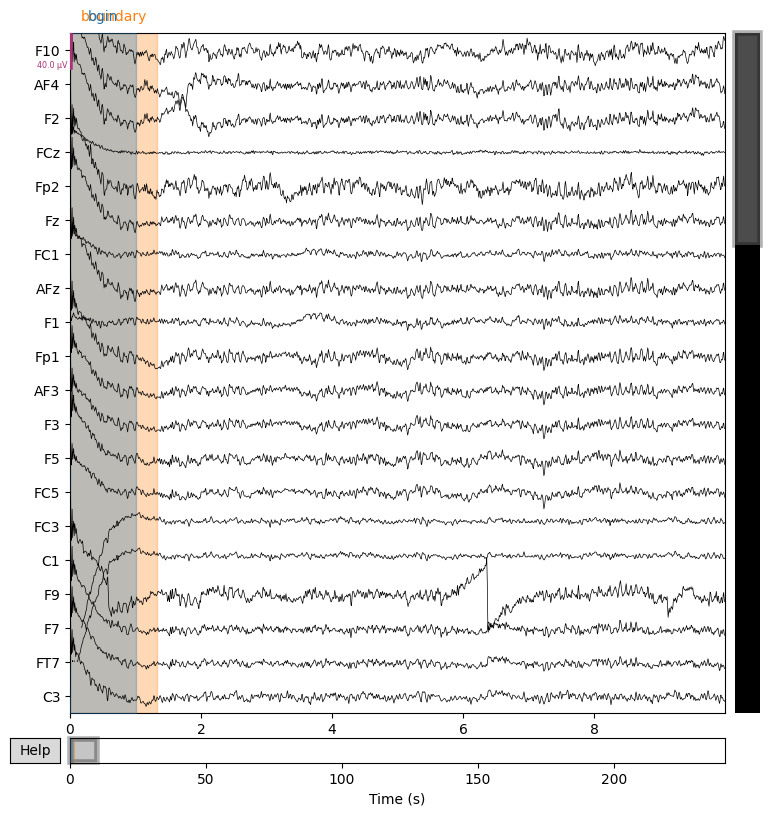

In [67]:
print("ICA After")
cleaned.plot(duration=10, n_channels=20)

In [68]:
epochs = mne.make_fixed_length_epochs(
    cleaned,
    duration=2.0,
    overlap=0,
    preload=True
)

Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 120 events and 500 original time points ...
0 bad epochs dropped


In [69]:
print(epochs)

<Epochs | 120 events (all good), 0 – 1.996 s (baseline off), ~29.4 MiB, data loaded,
 '1': 120>


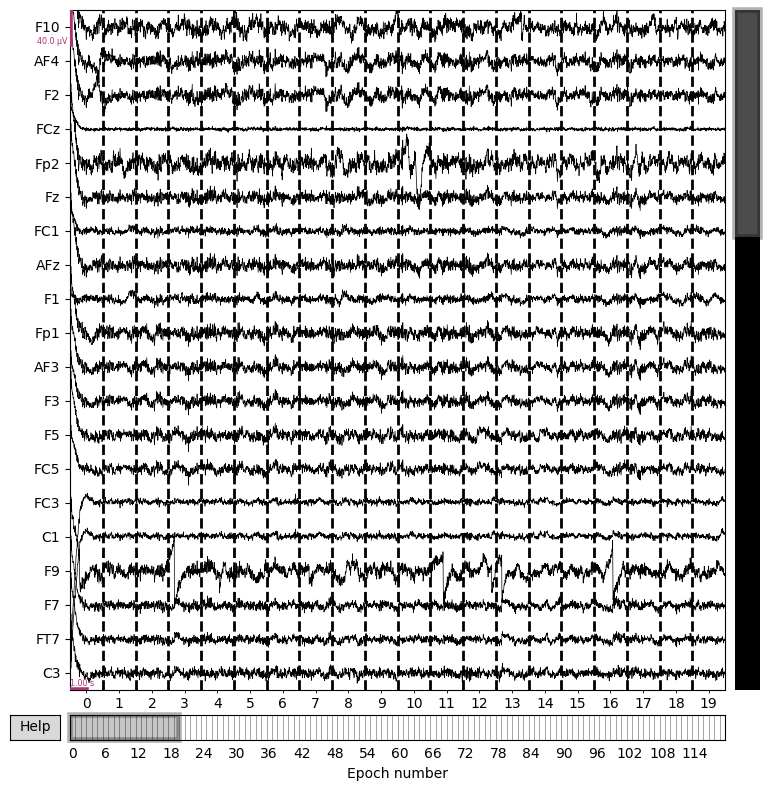

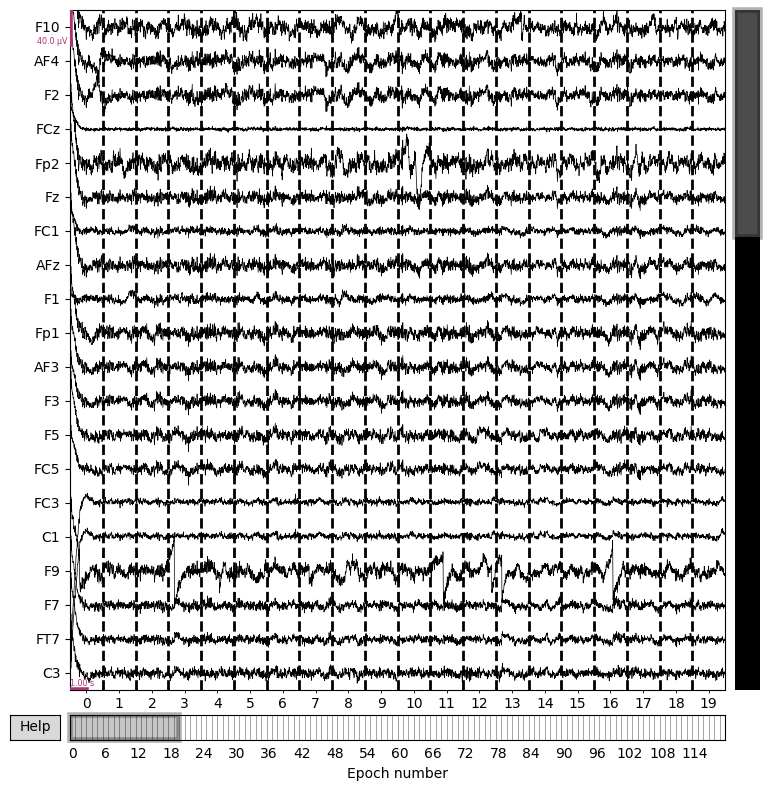

In [70]:
epochs.plot()

In [71]:
X = epochs.get_data()
print("(num_epochs, channels, timepoints)")

print(X.shape)

(num_epochs, channels, timepoints)
(120, 64, 500)


In [72]:
if "rest" in sample_file:
    label = 0

elif "walk" in sample_file:
    label = 1

print(label)

0


In [73]:
X_list = []
y_list = []
subject_list = []

In [74]:
import gc

X_list = []
y_list = []
subject_list = []

for file in eeg_files:

    try:

        print(f"\nProcessing: {os.path.basename(file)}")

        # =========================================
        # LOAD EEG
        # =========================================

        raw = load_eeg(file)

        # =========================================
        # DROP VREF CHANNEL
        # =========================================
        
        if "VREF" in raw.ch_names:
            raw.drop_channels(["VREF"])
        
        # =========================================
        # DROP EOG CHANNELS
        # =========================================
        
        eog_channels = [
            "EOG1",
            "EOG2",
            "EOG3",
            "EOG4"
        ]
        
        existing_eog = [
            ch for ch in eog_channels
            if ch in raw.ch_names
        ]
        
        raw.drop_channels(existing_eog)

        # =========================================
        # SET MONTAGE
        # =========================================

        montage = mne.channels.make_standard_montage(
            "standard_1020"
        )

        raw.set_montage(
            montage,
            on_missing="ignore"
        )

        # =========================================
        # BANDPASS FILTER
        # =========================================

        raw.filter(
            l_freq=1,
            h_freq=40,
            verbose=False
        )

        # =========================================
        # NOTCH FILTER
        # =========================================

        raw.notch_filter(
            freqs=50,
            verbose=False
        )

        # =========================================
        # CREATE EPOCHS
        # =========================================

        epochs = mne.make_fixed_length_epochs(
            raw,
            duration=2.0,
            overlap=0,
            preload=True
        )

        # =========================================
        # EXTRACT NUMPY DATA
        # =========================================

        X = epochs.get_data().astype(np.float32)

        print("Epoch shape:", X.shape)

        # =========================================
        # LABEL EXTRACTION
        # =========================================

        if "rest" in file.lower():

            label = 0

        elif "walk" in file.lower():

            label = 1

        else:

            continue

        # =========================================
        # SUBJECT ID
        # =========================================

        filename = os.path.basename(file)

        subject_id = filename.split("_")[0]

        # =========================================
        # STORE EPOCHS
        # =========================================

        for epoch in X:

            X_list.append(epoch)

            y_list.append(label)

            subject_list.append(subject_id)

        print(f"Stored {len(X)} epochs")

        print("Current Dataset Size:", len(X_list))

        # =========================================
        # MEMORY CLEANUP
        # =========================================

        del raw
        del epochs
        del X

        gc.collect()

    except Exception as e:

        print(f"\nERROR: {file}")

        print(e)


Processing: sub-093_task-rest_eeg.set
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 120 events and 500 original time points ...
0 bad epochs dropped
Epoch shape: (120, 60, 500)
Stored 120 epochs
Current Dataset Size: 120

Processing: sub-093_task-walk_eeg.set
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 120 events and 500 original time points ...
0 bad epochs dropped
Epoch shape: (120, 60, 500)
Stored 120 epochs
Current Dataset Size: 240

Processing: sub-128_task-walk_eeg.set
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 120 events and 500 original time points ...
0 bad epochs dropped
Epoch shape: (120, 60, 500)
Stored 120 epochs
Current Dataset Size: 360

Processing: sub-128_task-rest_eeg.set
Not settin

In [75]:
print(len(X_list))
print(len(y_list))
print(len(subject_list))

34904
34904
34904


In [76]:
X = np.array(X_list, dtype=np.float32)

print(X.shape)

del X_list

gc.collect()

(34904, 60, 500)


0

In [77]:
y = np.array(y_list, dtype=np.int32)

subjects = np.array(subject_list)

print(y.shape)
print(subjects.shape)

del y_list
del subject_list

gc.collect()

(34904,)
(34904,)


0

In [78]:
print(X.shape)
print(y.shape)
print(subjects.shape)

(34904, 60, 500)
(34904,)
(34904,)


In [79]:
pd.Series(y).value_counts()

1    17545
0    17359
Name: count, dtype: int64

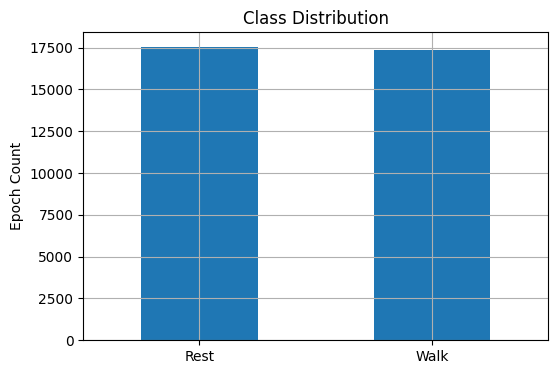

In [80]:
plt.figure(figsize=(6,4))

pd.Series(y).value_counts().plot(
    kind="bar"
)

plt.xticks(
    [0,1],
    ["Rest", "Walk"],
    rotation=0
)

plt.ylabel("Epoch Count")

plt.title("Class Distribution")

plt.grid(True)

plt.show()

In [81]:
np.save("/kaggle/working/X.npy", X)

np.save("/kaggle/working/y.npy", y)

np.save("/kaggle/working/subjects.npy", subjects)

print("Saved Successfully")

Saved Successfully


## SUBJECT-WISE SPLIT

In [82]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=subjects)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print(X_train.shape)
print(X_test.shape)

(28393, 60, 500)
(6511, 60, 500)


In [83]:
# =========================================
# ADD CNN CHANNEL DIMENSION
# =========================================

X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print(X_train.shape)

# =========================================
# TRANSPOSE FOR EEGNET
# =========================================

X_train = np.transpose(
    X_train,
    (0, 2, 1, 3)
)

X_test = np.transpose(
    X_test,
    (0, 2, 1, 3)
)

print(X_train.shape)
print(X_test.shape)

(28393, 60, 500, 1)
(28393, 500, 60, 1)
(6511, 500, 60, 1)


In [84]:
X_train = np.transpose(
    X_train,
    (0, 2, 1, 3)
)

X_test = np.transpose(
    X_test,
    (0, 2, 1, 3)
)

print(X_train.shape)

(28393, 60, 500, 1)


# Create Smaller Subset

Due to low memory issue

In [85]:
subset_size = 10000

X_small = X[:subset_size]

y_small = y[:subset_size]

subjects_small = subjects[:subset_size]

print(X_small.shape)

(10000, 60, 500)


In [86]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        X_small,
        y_small,
        groups=subjects_small
    )
)

X_train = X_small[train_idx]
X_test = X_small[test_idx]

y_train = y_small[train_idx]
y_test = y_small[test_idx]

In [87]:
del X
del y
del subjects

gc.collect()

print("Memory cleared")

Memory cleared


# Baselines

In [88]:
results = []

## Lightweight CSP + Linear SVM

In [89]:
from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

csp = CSP(
    n_components=8,
    log=True,
    norm_trace=False
)

clf = Pipeline([
    ("CSP", csp),
    ("SVM", LinearSVC(
        class_weight="balanced",
        max_iter=5000
    ))
])

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred))

from sklearn.metrics import accuracy_score, f1_score

results.append({

    "Model": "CSP + LinearSVC",

    "Configuration": "EEG Only",

    "Accuracy": accuracy_score(
        y_test,
        y_pred
    ),

    "Macro F1-Score": f1_score(
        y_test,
        y_pred,
        average='macro'
    )

})

Computing rank from data with rank=None
    Using tolerance 0.019 (2.2e-16 eps * 60 dim * 1.4e+12  max singular value)
    Estimated rank (data): 60
    data: rank 60 computed from 60 data channels with 0 projectors
Reducing data rank from 60 -> 60
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Accuracy: 0.7710963455149502

Classification Report:

              precision    recall  f1-score   support

           0       0.59      0.92      0.72       963
           1       0.95      0.70      0.81      2047

    accuracy                           0.77      3010
   macro avg       0.77      0.81      0.76      3010
weighted avg       0.83      0.77      0.78      3010



## Random Forest

In [90]:
X_train_flat = X_train.reshape(
    X_train.shape[0],
    -1
)

X_test_flat = X_test.reshape(
    X_test.shape[0],
    -1
)

In [91]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    n_jobs=-1,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_flat, y_train)

y_pred = rf_model.predict(X_test_flat)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

results.append({

    "Model": "Random Forest",

    "Configuration": "EEG Only",

    "Accuracy": accuracy_score(
        y_test,
        y_pred
    ),

    "Macro F1-Score": f1_score(
        y_test,
        y_pred,
        average='macro'
    )

})

Accuracy: 0.6006644518272425
              precision    recall  f1-score   support

           0       0.43      0.77      0.55       963
           1       0.83      0.52      0.64      2047

    accuracy                           0.60      3010
   macro avg       0.63      0.64      0.60      3010
weighted avg       0.70      0.60      0.61      3010



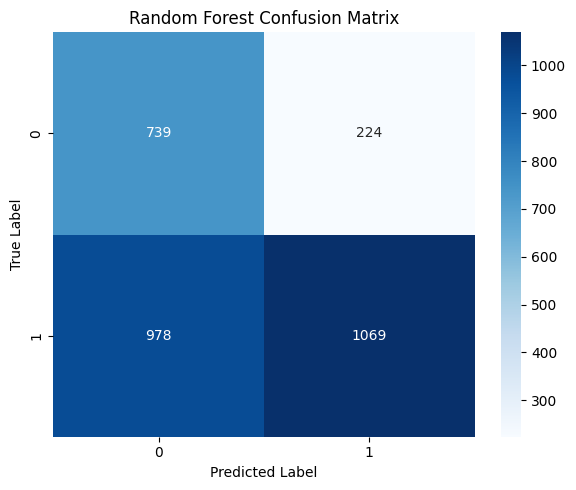

In [92]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# =====================================
# CONFUSION MATRIX
# =====================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Label")

plt.ylabel("True Label")

plt.title("Random Forest Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/rf_confusion_matrix.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## MEMORY-SAFE XGBOOST

In [93]:
!pip install xgboost -q

In [94]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_model.fit(X_train_flat, y_train)

y_pred = xgb_model.predict(X_test_flat)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred))

results.append({

    "Model": "XGBoost",

    "Configuration": "EEG Only",

    "Accuracy": accuracy_score(
        y_test,
        y_pred
    ),

    "Macro F1-Score": f1_score(
        y_test,
        y_pred,
        average='macro'
    )

})

Accuracy: 0.7026578073089701

Classification Report:

              precision    recall  f1-score   support

           0       0.52      0.85      0.65       963
           1       0.90      0.63      0.74      2047

    accuracy                           0.70      3010
   macro avg       0.71      0.74      0.69      3010
weighted avg       0.78      0.70      0.71      3010



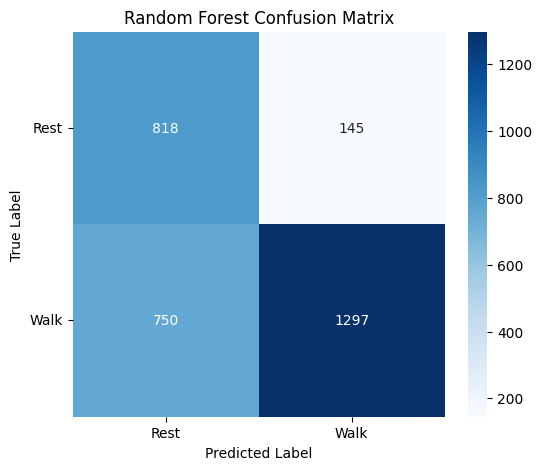

In [95]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0.5, 1.5],
    ["Rest", "Walk"]
)

plt.yticks(
    [0.5, 1.5],
    ["Rest", "Walk"],
    rotation=0
)

plt.title("Random Forest Confusion Matrix")

plt.show()

ROC-AUC Score: 0.705038044175784


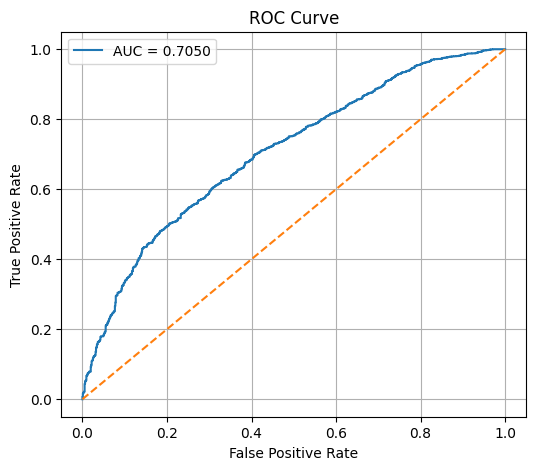

In [96]:
from sklearn.metrics import roc_curve, roc_auc_score

# probability scores
y_probs = rf_model.predict_proba(X_test_flat)[:,1]

# ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probs
)

# AUC
auc_score = roc_auc_score(
    y_test,
    y_probs
)

print("ROC-AUC Score:", auc_score)

# Plot
plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

In [97]:
import numpy as np

importance = rf_model.feature_importances_

print("Feature vector shape:")
print(importance.shape)

Feature vector shape:
(30000,)


In [98]:
sample_raw = load_eeg(eeg_files[0])

if "VREF" in sample_raw.ch_names:
    sample_raw.drop_channels(["VREF"])

channel_names = sample_raw.ch_names

print(len(channel_names))

64


In [99]:
sample_raw = load_eeg(eeg_files[0])

# remove VREF
if "VREF" in sample_raw.ch_names:
    sample_raw.drop_channels(["VREF"])

# remove EOG
eog_channels = [
    "EOG1",
    "EOG2",
    "EOG3",
    "EOG4"
]

existing_eog = [
    ch for ch in eog_channels
    if ch in sample_raw.ch_names
]

sample_raw.drop_channels(existing_eog)

channel_names = sample_raw.ch_names

print(len(channel_names))

60


In [100]:
importance_2d = importance.reshape(60, 500)

channel_importance = importance_2d.mean(axis=1)

channel_df = pd.DataFrame({
    "Channel": channel_names,
    "Importance": channel_importance
})

channel_df = channel_df.sort_values(
    by="Importance",
    ascending=False
)

channel_df.head(10)

,Channel,Importance
38,O2,0.000264
9,Fp1,0.000261
4,Fp2,0.000225
6,FC1,0.000124
52,FC4,0.000100
7,AFz,0.000083
46,TP10,0.000076
30,P1,0.000041
5,Fz,0.000033
1,AF4,0.000028


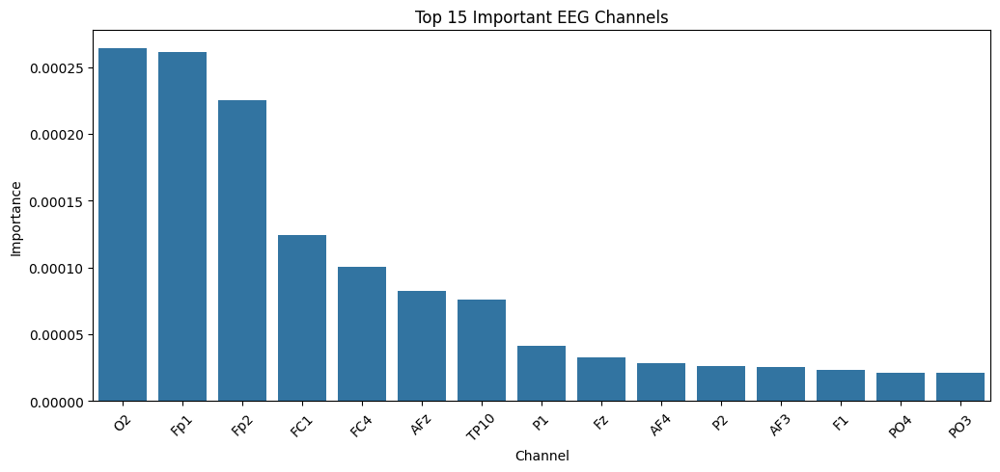

In [101]:
plt.figure(figsize=(12,5))

sns.barplot(
    x="Channel",
    y="Importance",
    data=channel_df.head(15)
)

plt.title("Top 15 Important EEG Channels")

plt.xticks(rotation=45)

plt.show()

In [102]:
test_subjects = subjects_small[test_idx]

In [103]:
subject_results = []

unique_subjects = np.unique(test_subjects)

for subj in unique_subjects:

    mask = test_subjects == subj

    subj_acc = (
        y_pred[mask] == y_test[mask]
    ).mean()

    subject_results.append({
        "Subject": subj,
        "Accuracy": subj_acc
    })

subject_df = pd.DataFrame(subject_results)

subject_df.head()

,Subject,Accuracy
0,sub-014,0.495868
1,sub-018,0.909091
2,sub-057,0.661157
3,sub-103,0.795833
4,sub-110,0.589360


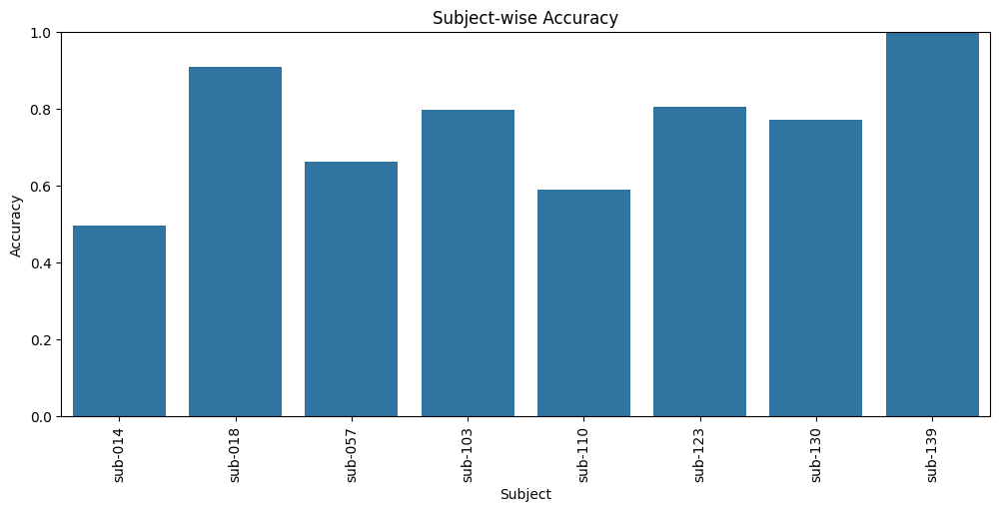

In [104]:
plt.figure(figsize=(12,5))

sns.barplot(
    x="Subject",
    y="Accuracy",
    data=subject_df
)

plt.xticks(rotation=90)

plt.ylim(0,1)

plt.title("Subject-wise Accuracy")

plt.show()

In [105]:
# results_df = pd.DataFrame({

#     "Model": [
#         "CSP + LinearSVC",
#         "Random Forest",
#         "XGBoost",
#         "CSP + LinearSVC",
#         "Random Forest",
#         "XGBoost"
#     ],

#     "Configuration": [
#         "EEG + EOG",
#         "EEG + EOG",
#         "EEG + EOG",
#         "EEG Only",
#         "EEG Only",
#         "EEG Only"
#     ],

#     "Accuracy": [
#         0.7707,
#         0.8976,
#         0.7754,
#         0.7711,
#         0.6007,
#         0.7027
#     ],

#     "Macro F1-Score": [
#         0.76,
#         0.88,
#         0.76,
#         0.76,
#         0.60,
#         0.69
#     ]

# })

# results_df

### Sanity checks befor EEGNet

In [106]:
X = np.load(
    "/kaggle/working/X.npy",
    mmap_mode='r'
)

y = np.load(
    "/kaggle/working/y.npy",
    mmap_mode='r'
)

subjects = np.load(
    "/kaggle/working/subjects.npy",
    mmap_mode='r'
)

In [107]:
subset_size = 8000

X_small = np.array(
    X[:subset_size],
    dtype=np.float32
)

y_small = np.array(
    y[:subset_size]
)

subjects_small = np.array(
    subjects[:subset_size]
)

In [108]:
del X
del y
del subjects

gc.collect()

4684

In [109]:
X_small = X_small[..., np.newaxis]

print(X_small.shape)

(8000, 60, 500, 1)


In [110]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        X_small,
        y_small,
        groups=subjects_small
    )
)

X_train = X_small[train_idx]
X_test = X_small[test_idx]

y_train = y_small[train_idx]
y_test = y_small[test_idx]

## EEGNet

In [111]:
X_train = np.transpose(
    X_train,
    (0, 2, 1, 3)
)

X_test = np.transpose(
    X_test,
    (0, 2, 1, 3)
)

print(X_train.shape)

(6315, 500, 60, 1)


In [112]:
import tensorflow as tf

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    DepthwiseConv2D,
    AveragePooling2D,
    SeparableConv2D,
    BatchNormalization,
    Dropout,
    Activation,
    Flatten,
    Dense
)

from tensorflow.keras.constraints import max_norm

from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

2026-05-12 11:00:15.015055: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778583615.156100    2300 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778583615.207278    2300 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778583615.656668    2300 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778583615.656702    2300 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778583615.656704    2300 computation_placer.cc:177] computation placer alr

In [113]:
def EEGNet(

    nb_classes=2,
    Chans=60,
    Samples=500,
    dropoutRate=0.5,
    kernLength=64,
    F1=8,
    D=2,
    F2=16

):

    input1 = Input(shape=(Samples, Chans, 1))

    # =====================================================
    # BLOCK 1
    # =====================================================

    block1 = Conv2D(
        F1,
        (1, kernLength),
        padding='same',
        use_bias=False
    )(input1)

    block1 = BatchNormalization()(block1)

    block1 = DepthwiseConv2D(
        (1, Chans),
        use_bias=False,
        depth_multiplier=D,
        depthwise_constraint=max_norm(1.)
    )(block1)

    block1 = BatchNormalization()(block1)

    block1 = Activation('elu')(block1)

    block1 = AveragePooling2D((4, 1))(block1)

    block1 = Dropout(dropoutRate)(block1)

    # =====================================================
    # BLOCK 2
    # =====================================================

    block2 = SeparableConv2D(
        F2,
        (1, 16),
        use_bias=False,
        padding='same'
    )(block1)

    block2 = BatchNormalization()(block2)

    block2 = Activation('elu')(block2)

    block2 = AveragePooling2D((8, 1))(block2)

    block2 = Dropout(dropoutRate)(block2)

    # =====================================================
    # CLASSIFIER
    # =====================================================

    flatten = Flatten()(block2)

    dense = Dense(
        nb_classes,
        kernel_constraint=max_norm(0.25)
    )(flatten)

    softmax = Activation('softmax')(dense)

    return Model(inputs=input1, outputs=softmax)

In [114]:
model = EEGNet(
    nb_classes=2,
    Chans=60,
    Samples=500
)

model.summary()

I0000 00:00:1778583627.523468    2300 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1778583627.528536    2300 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 500, 60, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 500, 60, 8)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 500, 60, 8)     │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 500, 1, 16)     │           960 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 500, 1, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 500, 1, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 125, 1, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 125, 1, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 125, 1, 16)     │           512 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 125, 1, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 125, 1, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 15, 1, 16)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 15, 1, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 240)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           482 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,626 (10.26 KB)

 Trainable params: 2,546 (9.95 KB)

 Non-trainable params: 80 (320.00 B)

In [115]:
model.compile(

    loss='sparse_categorical_crossentropy',

    optimizer=Adam(learning_rate=0.0005),

    metrics=['accuracy']
)

In [116]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

print("Shapes one last time: ")
print(X_train.shape)
print(X_test.shape)

history = model.fit(

    X_train,
    y_train,

    validation_data=(X_test, y_test),

    epochs=100,

    batch_size=16,

    callbacks=[early_stop],

    verbose=1
)

Shapes one last time: 
(6315, 500, 60, 1)
(1685, 500, 60, 1)
Epoch 1/100


I0000 00:00:1778583632.139754    2524 service.cc:152] XLA service 0x7f5094001da0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778583632.139806    2524 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1778583632.139811    2524 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1778583632.477248    2524 cuda_dnn.cc:529] Loaded cuDNN version 91002


  3/395 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.5868 - loss: 0.6862

I0000 00:00:1778583636.880245    2524 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


395/395 ━━━━━━━━━━━━━━━━━━━━ 26s 48ms/step - accuracy: 0.5396 - loss: 0.6769 - val_accuracy: 0.5009 - val_loss: 0.6932
Epoch 2/100
395/395 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.5887 - loss: 0.6161 - val_accuracy: 0.5015 - val_loss: 0.7225
Epoch 3/100
395/395 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.6391 - loss: 0.6046 - val_accuracy: 0.5009 - val_loss: 0.6899
Epoch 4/100
395/395 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.6925 - loss: 0.5760 - val_accuracy: 0.5039 - val_loss: 0.7140
Epoch 5/100
395/395 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.7233 - loss: 0.5550 - val_accuracy: 0.5021 - val_loss: 0.9522
Epoch 6/100
395/395 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.7197 - loss: 0.5598 - val_accuracy: 0.5021 - val_loss: 1.0314
Epoch 7/100
395/395 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.7240 - loss: 0.5485 - val_accuracy: 0.5021 - val_loss: 0.6924
Epoch 8/100
395/395 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.7434 - loss: 0.5324 - val_

In [117]:
y_probs = model.predict(X_test)

y_pred = np.argmax(y_probs, axis=1)

print(
    classification_report(
        y_test,
        y_pred
    )
)

results.append({

    "Model": "EEGNet",

    "Configuration": "EEG Only",

    "Accuracy": accuracy_score(
        y_test,
        y_pred
    ),

    "Macro F1-Score": f1_score(
        y_test,
        y_pred,
        average='macro'
    )

})

53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step
              precision    recall  f1-score   support

           0       1.00      0.00      0.00       843
           1       0.50      1.00      0.67       842

    accuracy                           0.50      1685
   macro avg       0.75      0.50      0.34      1685
weighted avg       0.75      0.50      0.34      1685



In [118]:
results_df = pd.DataFrame(results)

results_df

,Model,Configuration,Accuracy,Macro F1-Score
0,CSP + LinearSVC,EEG Only,0.771096,0.763040
1,Random Forest,EEG Only,0.600664,0.595806
2,XGBoost,EEG Only,0.702658,0.694932
3,EEGNet,EEG Only,0.500890,0.335832


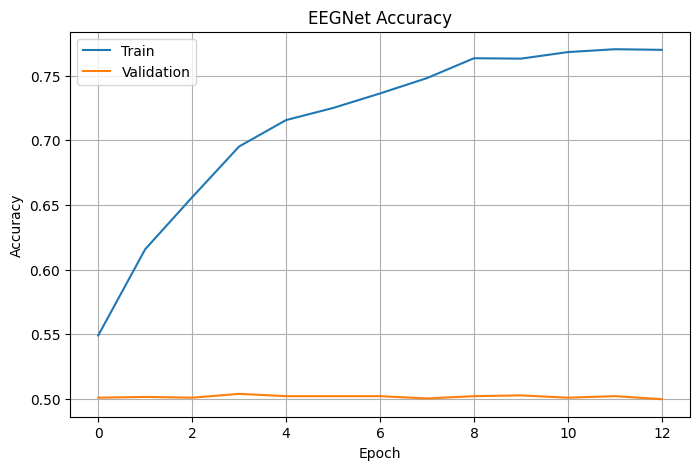

In [119]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'])

plt.plot(history.history['val_accuracy'])

plt.title("EEGNet Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend([
    "Train",
    "Validation"
])

plt.grid(True)

plt.show()

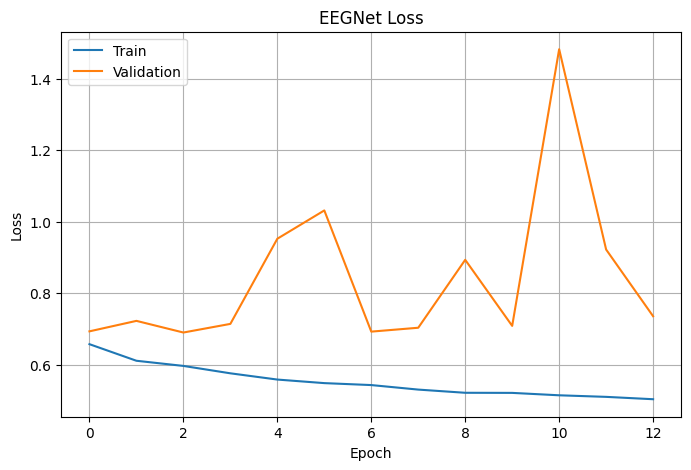

In [120]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'])

plt.plot(history.history['val_loss'])

plt.title("EEGNet Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend([
    "Train",
    "Validation"
])

plt.grid(True)

plt.show()

In [121]:
y_probs = model.predict(X_test)

y_pred = np.argmax(
    y_probs,
    axis=1
)

53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [122]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

acc = accuracy_score(
    y_test,
    y_pred
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average='macro'
)

print(f"Accuracy: {acc:.4f}")

print(f"Macro F1: {macro_f1:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred
    )
)

Accuracy: 0.5009
Macro F1: 0.3358

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.00      0.00       843
           1       0.50      1.00      0.67       842

    accuracy                           0.50      1685
   macro avg       0.75      0.50      0.34      1685
weighted avg       0.75      0.50      0.34      1685



In [123]:
results.append({

    "Model": "EEGNet",

    "Configuration": "EEG Only",

    "Accuracy": acc,

    "Macro F1-Score": macro_f1

})

In [124]:
results_df = pd.DataFrame(results)

results_df

,Model,Configuration,Accuracy,Macro F1-Score
0,CSP + LinearSVC,EEG Only,0.771096,0.763040
1,Random Forest,EEG Only,0.600664,0.595806
2,XGBoost,EEG Only,0.702658,0.694932
3,EEGNet,EEG Only,0.500890,0.335832
4,EEGNet,EEG Only,0.500890,0.335832


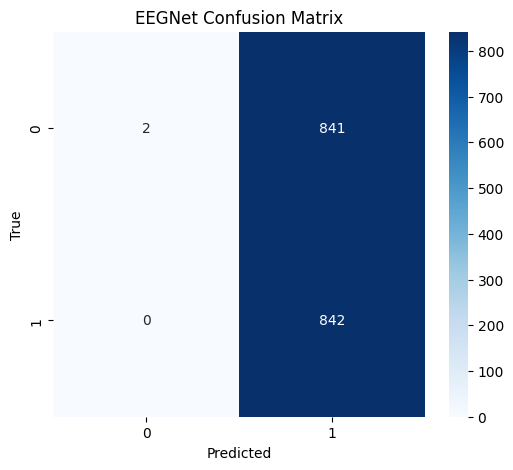

In [125]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("EEGNet Confusion Matrix")

plt.show()

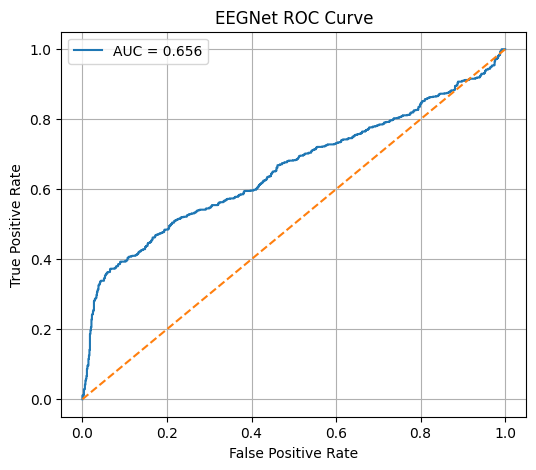

In [126]:
from sklearn.metrics import (
    roc_curve,
    auc
)

fpr, tpr, _ = roc_curve(
    y_test,
    y_probs[:,1]
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("EEGNet ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

In [130]:
print(len(channel_names))

print(len(channel_importance))

59
60


In [134]:
channel_importance = channel_importance[:59]

In [135]:
print(len(channel_names))

print(len(channel_importance))

60
59


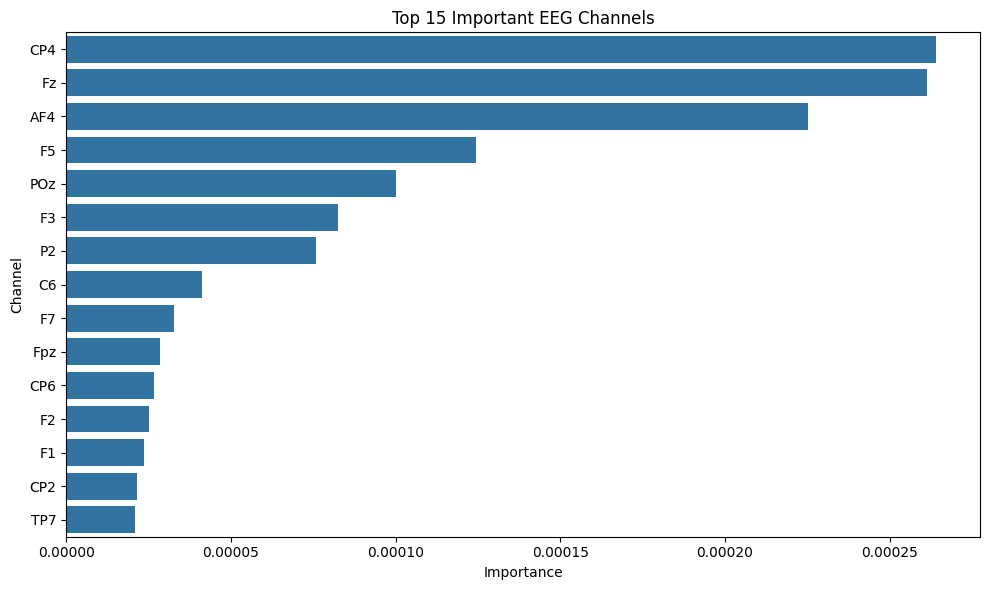

In [136]:
channel_names = [

    'Fp1','Fpz','Fp2','AF3','AF4',
    'F7','F5','F3','F1','Fz',
    'F2','F4','F6','F8',
    'FT7','FC5','FC3','FC1','FCz',
    'FC2','FC4','FC6','FT8',
    'T7','C5','C3','C1','Cz',
    'C2','C4','C6','T8',
    'TP7','CP5','CP3','CP1','CPz',
    'CP2','CP4','CP6','TP8',
    'P7','P5','P3','P1','Pz',
    'P2','P4','P6','P8',
    'PO7','PO3','POz','PO4','PO8',
    'O1','Oz','O2','Iz'
]

channel_df = pd.DataFrame({

    "Channel": channel_names,

    "Importance": channel_importance

})

channel_df = channel_df.sort_values(
    "Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(

    x="Importance",

    y="Channel",

    data=channel_df.head(15)

)

plt.title("Top 15 Important EEG Channels")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/channel_importance.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [146]:
# =========================================
# CREATE FOLDER
# =========================================

import os

save_dir = "/kaggle/working/results"

os.makedirs(save_dir, exist_ok=True)

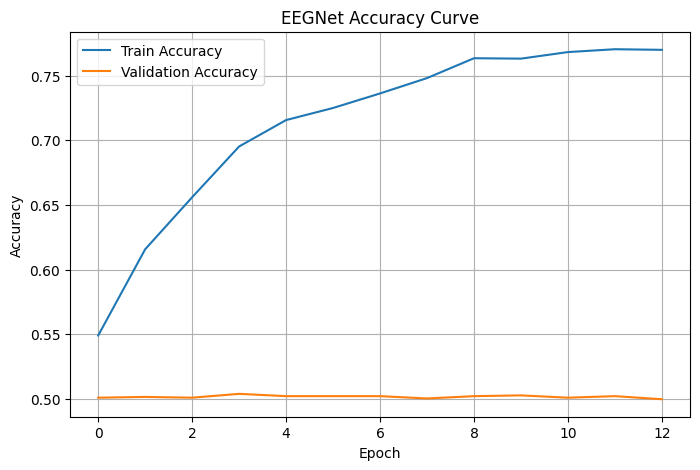

In [147]:
# =========================================
# EEGNET ACCURACY CURVE
# =========================================

plt.figure(figsize=(8,5))

plt.plot(
    history.history['accuracy'],
    label='Train Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("EEGNet Accuracy Curve")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.savefig(
    f"{save_dir}/eegnet_accuracy_curve.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

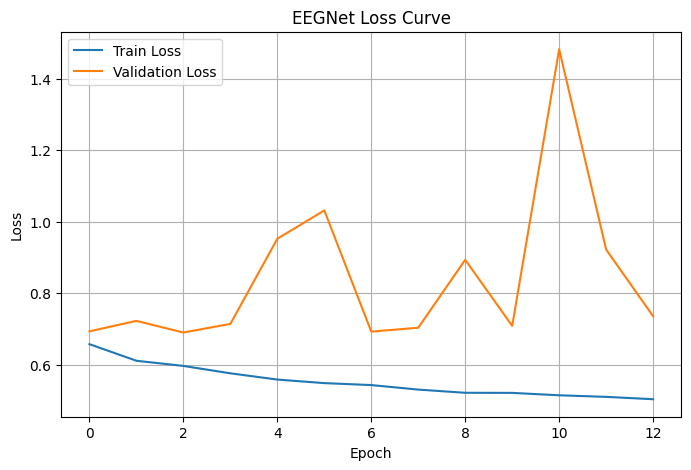

In [148]:
# =========================================
# EEGNET LOSS CURVE
# =========================================

plt.figure(figsize=(8,5))

plt.plot(
    history.history['loss'],
    label='Train Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("EEGNet Loss Curve")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.savefig(
    f"{save_dir}/eegnet_loss_curve.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [151]:
# =========================================
# SAVE RESULTS TABLE
# =========================================

results_df.to_csv(
    f"{save_dir}/results_summary.csv",
    index=False
)

In [152]:
import pickle

with open(
    "/kaggle/working/eegnet_history.pkl",
    "wb"
) as f:

    pickle.dump(
        history.history,
        f
    )

np.save(
    "/kaggle/working/eegnet_y_pred.npy",
    y_pred
)

np.save(
    "/kaggle/working/eegnet_y_test.npy",
    y_test
)

In [26]:
import sys
import select

# =====================================
# USER CONFIRMATION WITH 10s TIMEOUT
# =====================================

print(
    "\nType YES within 10 seconds to continue further analysis..."
)

ready, _, _ = select.select(
    [sys.stdin],
    [],
    [],
    10
)

if ready:

    user_input = sys.stdin.readline().strip().upper()

    if user_input == "YES":

        print("\nContinuing notebook execution...")

    else:

        print(
            "\nInvalid input. Stopping execution."
        )

        sys.exit()

else:

    print(
        "\nNo input received within 10 seconds."
    )

    print(
        "Stopping execution. You can now safely restart the kernel before KFold."
    )

    sys.exit()


Type YES within 10 seconds to continue further analysis...

Invalid input. Stopping execution.


SystemExit: 

/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [1]:
## Start KFOLD

In [2]:
import numpy as np
import pandas as pd
import gc

from sklearn.model_selection import GroupKFold

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

from sklearn.pipeline import Pipeline

from sklearn.svm import LinearSVC

from mne.decoding import CSP

In [3]:
# =====================================
# LOAD ARRAYS USING MEMORY MAP
# =====================================

X = np.load(
    "/kaggle/working/X.npy",
    mmap_mode='r'
)

y = np.load(
    "/kaggle/working/y.npy",
    mmap_mode='r'
)

subjects = np.load(
    "/kaggle/working/subjects.npy",
    mmap_mode='r'
)

# =====================================
# VERIFY SHAPES
# =====================================

print("X shape:", X.shape)

print("y shape:", y.shape)

print("subjects shape:", subjects.shape)

print("dtype:", X.dtype)

X shape: (34904, 60, 500)
y shape: (34904,)
subjects shape: (34904,)
dtype: float32


### CREATE SMALLER BALANCED DATASET

In [4]:
# =====================================
# CREATE METADATA DATAFRAME
# =====================================

meta_df = pd.DataFrame({

    "Index": np.arange(len(y)),

    "Label": y,

    "Subject": subjects

})

# =====================================
# BALANCED SUBSAMPLING
# =====================================

samples_per_class = 4000

rest_idx = meta_df[
    meta_df["Label"] == 0
].sample(
    samples_per_class,
    random_state=42
)["Index"]

walk_idx = meta_df[
    meta_df["Label"] == 1
].sample(
    samples_per_class,
    random_state=42
)["Index"]

selected_idx = np.concatenate([
    rest_idx,
    walk_idx
])

np.random.shuffle(selected_idx)

# =====================================
# CREATE SMALLER ARRAYS
# =====================================

X_small = np.array(
    X[selected_idx],
    dtype=np.float32
)

y_small = np.array(
    y[selected_idx]
)

subjects_small = np.array(
    subjects[selected_idx]
)

# =====================================
# VERIFY
# =====================================

print("X_small shape:", X_small.shape)

print("y_small shape:", y_small.shape)

print("subjects_small shape:", subjects_small.shape)

X_small shape: (8000, 60, 500)
y_small shape: (8000,)
subjects_small shape: (8000,)


In [5]:
# =====================================
# DELETE ORIGINAL REFERENCES
# =====================================

del X
del y
del subjects
del meta_df
del rest_idx
del walk_idx
del selected_idx

# =====================================
# GARBAGE COLLECTION
# =====================================

gc.collect()

print("Original references deleted.")

Original references deleted.


In [6]:
print(X_small.nbytes / 1024**3)

0.8940696716308594


CREATE GROUPKFOLD

In [7]:
# =====================================
# GROUPKFOLD
# =====================================

gkf = GroupKFold(
    n_splits=5
)

print(gkf)

GroupKFold(n_splits=5, random_state=None, shuffle=False)


CSP + LinearSVC GroupKFold evaluation

In [8]:
# =====================================
# STORE RESULTS
# =====================================

accuracies = []

macro_f1s = []

fold = 1

# =====================================
# GROUPKFOLD LOOP
# =====================================

for train_idx, test_idx in gkf.split(
    X_small,
    y_small,
    groups=subjects_small
):

    print(f"\n========== Fold {fold} ==========")

    # =====================================
    # SPLIT CURRENT FOLD
    # =====================================

    X_train = X_small[train_idx]

    X_test = X_small[test_idx]

    y_train = y_small[train_idx]

    y_test = y_small[test_idx]

    # =====================================
    # CSP + LINEARSVC PIPELINE
    # =====================================

    clf = Pipeline([

        (
            "CSP",

            CSP(
                n_components=8,
                log=True
            )
        ),

        (
            "SVM",

            LinearSVC()
        )

    ])

    # =====================================
    # TRAIN
    # =====================================

    clf.fit(
        X_train,
        y_train
    )

    # =====================================
    # PREDICT
    # =====================================

    y_pred = clf.predict(X_test)

    # =====================================
    # METRICS
    # =====================================

    acc = accuracy_score(
        y_test,
        y_pred
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='macro'
    )

    accuracies.append(acc)

    macro_f1s.append(f1)

    print(f"Accuracy: {acc:.4f}")

    print(f"Macro F1: {f1:.4f}")

    # =====================================
    # CLEANUP
    # =====================================

    del X_train
    del X_test
    del y_train
    del y_test
    del y_pred
    del clf

    gc.collect()

    fold += 1


========== Fold 1 ==========
Computing rank from data with rank=None
    Using tolerance 0.055 (2.2e-16 eps * 60 dim * 4.1e+12  max singular value)
    Estimated rank (data): 60
    data: rank 60 computed from 60 data channels with 0 projectors
Reducing data rank from 60 -> 60
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Accuracy: 0.8038
Macro F1: 0.8032

========== Fold 2 ==========
Computing rank from data with rank=None
    Using tolerance 0.015 (2.2e-16 eps * 60 dim * 1.1e+12  max singular value)
    Estimated rank (data): 60
    data: rank 60 computed from 60 data channels with 0 projectors
Reducing data rank from 60 -> 60
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Accuracy: 0.8273
Macro F1: 0.8272

========== Fold 3 ==========
Computing rank from data with rank=None
    Using tolerance 0.055 (2.2e-16 eps * 60 dim * 4.1e+12  max singular value)
    Estimated ran

COMPUTE FINAL CV RESULTS

In [9]:
# =====================================
# FINAL CROSS-VALIDATION RESULTS
# =====================================

print("\n===== FINAL GROUPKFOLD RESULTS =====")

print(
    f"Mean Accuracy: "
    f"{np.mean(accuracies):.4f}"
)

print(
    f"Std Accuracy: "
    f"{np.std(accuracies):.4f}"
)

print(
    f"Mean Macro F1: "
    f"{np.mean(macro_f1s):.4f}"
)

print(
    f"Std Macro F1: "
    f"{np.std(macro_f1s):.4f}"
)


===== FINAL GROUPKFOLD RESULTS =====
Mean Accuracy: 0.7925
Std Accuracy: 0.0461
Mean Macro F1: 0.7915
Std Macro F1: 0.0470


visualize fold-wise performance

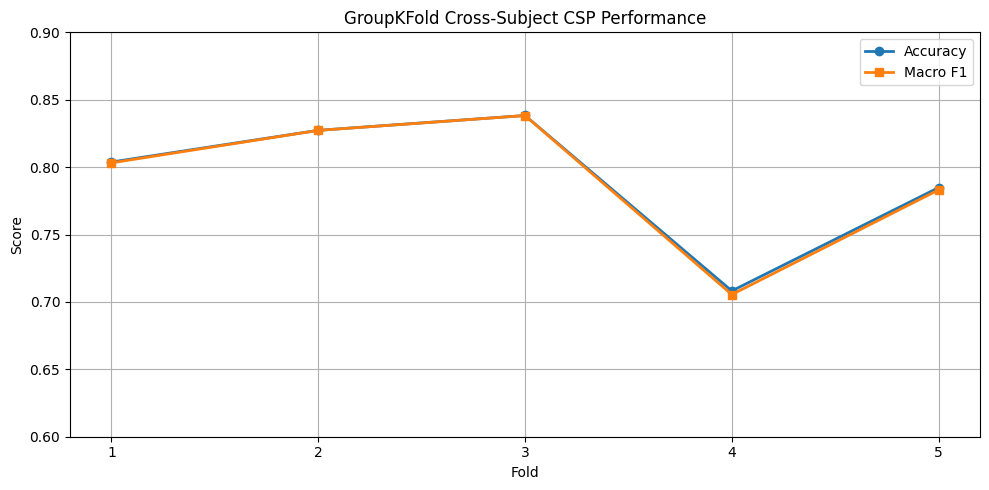

<Figure size 640x480 with 0 Axes>

In [11]:
# =====================================
# FOLD-WISE PERFORMANCE VISUALIZATION
# =====================================
import matplotlib.pyplot as plt

fold_numbers = np.arange(
    1,
    len(accuracies) + 1
)

plt.figure(figsize=(10,5))

plt.plot(
    fold_numbers,
    accuracies,
    marker='o',
    linewidth=2,
    label='Accuracy'
)

plt.plot(
    fold_numbers,
    macro_f1s,
    marker='s',
    linewidth=2,
    label='Macro F1'
)

plt.xticks(fold_numbers)

plt.ylim(0.6, 0.9)

plt.xlabel("Fold")

plt.ylabel("Score")

plt.title(
    "GroupKFold Cross-Subject CSP Performance"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

plt.savefig(
    "/kaggle/working/groupkfold_csp_performance.png",
    dpi=300,
    bbox_inches='tight'
)

In [12]:
import os

final_dir = "/kaggle/working/final_results"

os.makedirs(
    final_dir,
    exist_ok=True
)

print("Folder created.")

Folder created.


In [13]:
# =====================================
# SAVE KFOLD METRICS
# =====================================

kfold_results_df = pd.DataFrame({

    "Fold": np.arange(
        1,
        len(accuracies) + 1
    ),

    "Accuracy": accuracies,

    "Macro_F1": macro_f1s

})

kfold_results_df.to_csv(

    f"{final_dir}/groupkfold_csp_results.csv",

    index=False

)

kfold_results_df

,Fold,Accuracy,Macro_F1
0,1,0.803774,0.803171
1,2,0.827307,0.827242
2,3,0.838308,0.838244
3,4,0.708176,0.705485
4,5,0.784826,0.783135


In [14]:
results_df = pd.read_csv(
    "/kaggle/working/results/results_summary.csv"
)

results_df

,Model,Configuration,Accuracy,Macro F1-Score
0,CSP + LinearSVC,EEG Only,0.771096,0.763040
1,Random Forest,EEG Only,0.600664,0.595806
2,XGBoost,EEG Only,0.702658,0.694932
3,EEGNet,EEG Only,0.500890,0.335832
4,EEGNet,EEG Only,0.500890,0.335832


In [15]:
plt.savefig(

    f"{final_dir}/groupkfold_csp_performance.png",

    dpi=300,

    bbox_inches='tight'

)

<Figure size 640x480 with 0 Axes>

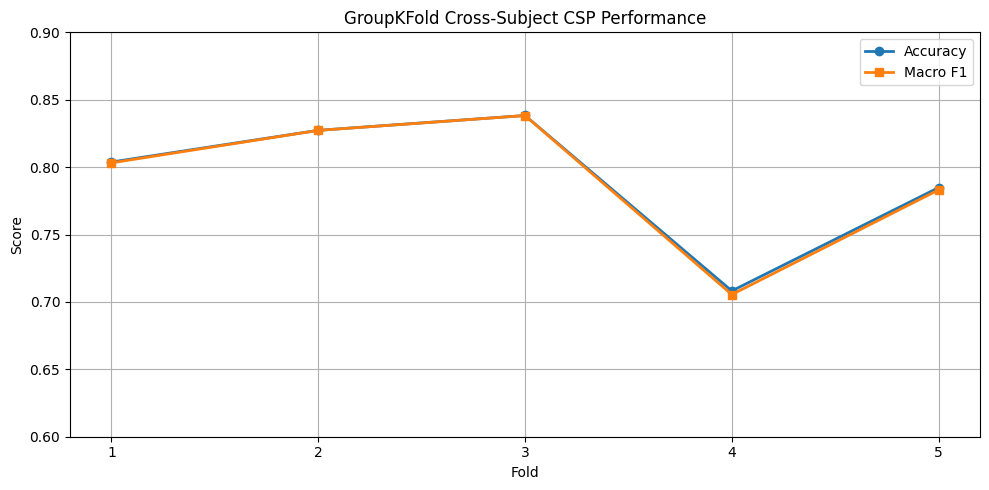

In [16]:
plt.figure(figsize=(10,5))

plt.plot(
    fold_numbers,
    accuracies,
    marker='o',
    linewidth=2,
    label='Accuracy'
)

plt.plot(
    fold_numbers,
    macro_f1s,
    marker='s',
    linewidth=2,
    label='Macro F1'
)

plt.xticks(fold_numbers)

plt.ylim(0.6, 0.9)

plt.xlabel("Fold")

plt.ylabel("Score")

plt.title(
    "GroupKFold Cross-Subject CSP Performance"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

# =====================================
# SAVE FIGURE
# =====================================

plt.savefig(

    f"{final_dir}/groupkfold_csp_performance.png",

    dpi=300,

    bbox_inches='tight'

)

plt.show()

In [17]:
summary_text = f"""

===== GROUPKFOLD CSP RESULTS =====

Mean Accuracy: {np.mean(accuracies):.4f}

Std Accuracy: {np.std(accuracies):.4f}

Mean Macro F1: {np.mean(macro_f1s):.4f}

Std Macro F1: {np.std(macro_f1s):.4f}

"""

with open(

    f"{final_dir}/groupkfold_summary.txt",

    "w"

) as f:

    f.write(summary_text)

print(summary_text)



===== GROUPKFOLD CSP RESULTS =====

Mean Accuracy: 0.7925

Std Accuracy: 0.0461

Mean Macro F1: 0.7915

Std Macro F1: 0.0470




In [18]:
np.save(
    f"{final_dir}/accuracies.npy",
    accuracies
)

np.save(
    f"{final_dir}/macro_f1s.npy",
    macro_f1s
)

print("Fold-wise arrays saved.")

Fold-wise arrays saved.


In [19]:
kfold_results_df = pd.DataFrame({

    "Fold": np.arange(
        1,
        len(accuracies) + 1
    ),

    "Accuracy": accuracies,

    "Macro_F1": macro_f1s

})

kfold_results_df.to_csv(

    f"{final_dir}/groupkfold_csp_results.csv",

    index=False

)

kfold_results_df

,Fold,Accuracy,Macro_F1
0,1,0.803774,0.803171
1,2,0.827307,0.827242
2,3,0.838308,0.838244
3,4,0.708176,0.705485
4,5,0.784826,0.783135


In [20]:
kfold_results_df.to_csv(

    "/kaggle/working/groupkfold_csp_results.csv",

    index=False

)

In [23]:
summary_text = f"""

===== GROUPKFOLD CSP RESULTS =====

Mean Accuracy: {np.mean(accuracies):.4f}

Std Accuracy: {np.std(accuracies):.4f}

Mean Macro F1: {np.mean(macro_f1s):.4f}

Std Macro F1: {np.std(macro_f1s):.4f}

"""

with open(
    "/kaggle/working/groupkfold_summary.txt",
    "w"
) as f:

    f.write(summary_text)

In [25]:
import os
import shutil

# =====================================
# CREATE PAPER ASSETS FOLDER
# =====================================

paper_dir = "/kaggle/working/paper_assets"

os.makedirs(
    paper_dir,
    exist_ok=True
)

# =====================================
# COPY ONLY PNG / CSV / TXT FILES
# =====================================

for root, dirs, files in os.walk("/kaggle/working"):

    # skip paper_assets itself
    if "paper_assets" in root:
        continue

    for file in files:

        if file.endswith((".png", ".csv", ".txt")):

            src = os.path.join(root, file)

            dst = os.path.join(paper_dir, file)

            shutil.copy(src, dst)

# =====================================
# CREATE ZIP
# =====================================

shutil.make_archive(

    "/kaggle/working/paper_assets",

    'zip',

    paper_dir

)

print("paper_assets.zip created successfully.")

paper_assets.zip created successfully.
